# CDS energy data — exercises

Hands-on practice with the Copernicus C3S Energy datasets and the `earthkit` /
`ecmwf-datastores-client` stack. Companion to `ecmwf.ipynb`, but self-contained.

## How to use this

Each task gives a **goal**, a **docs** line, and a **self-check**. The docs line is
deliberately narrow: usually the one page containing the answer, occasionally just an API
index when finding your way around _is_ the exercise. Read the linked page, not the site.

Where a check is `assert`-based, a silent pass means you got it right. The checks are
given to you — they are the spec. The implementations are yours.

Part S is deliberately thin: four steps, nothing you will not use within the hour. It
leaves you with a client, a collection and one DataFrame. Everything else — helper
functions, request dictionaries, constants — you write in Parts A–C at the moment the
repetition makes them obvious, and not before.

Rough budget: Part S ~30 min, A ~45 min, B ~1 h, C ~1.5 h.

## The stack

| library                   | role                                                     | docs                                                                                                                                                              |
| ------------------------- | -------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `ecmwf-datastores-client` | catalogue, form, constraints, cost, size-before-download | [API](https://ecmwf.github.io/ecmwf-datastores-client/_api/datastores/index.html) · [README](https://ecmwf.github.io/ecmwf-datastores-client/README.html)         |
| `earthkit-data`           | retrieve + cache + decode                                | [getting started](https://earthkit-data.readthedocs.io/en/latest/getting-started.html) · [API](https://earthkit-data.readthedocs.io/en/latest/api-reference.html) |
| `earthkit-meteo`          | derived meteorological quantities                        | [API](https://earthkit-meteo.readthedocs.io/en/latest/api-reference.html)                                                                                         |
| `earthkit-plots`          | quick maps and time series                               | [API](https://earthkit-plots.readthedocs.io/en/latest/api.html)                                                                                                   |

`cdsapi` is the **legacy** client — `cdsapi >= 0.7.2` is a thin shim over
`ecmwf-datastores-client`. Don't reach for it.

## Orientation — read these two first (~10 min)

- [earthkit-data: getting started](https://earthkit-data.readthedocs.io/en/latest/getting-started.html) — the `from_source` →
  decode → analyse flow in one page.
- [earthkit-data: migration to 1.0](https://earthkit-data.readthedocs.io/en/latest/release-notes/migration_1.0.0.html) — this
  environment runs 1.2, and 1.0 changed what `from_source` returns. Most tutorials you find
  online predate it.

## The datasets

| dataset                                                                                                       | what it is                                                    |
| ------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------- |
| [`sis-energy-global-reanalysis`](https://cds.climate.copernicus.eu/datasets/sis-energy-global-reanalysis)     | ERA5-derived, hourly, global, past only                       |
| [`sis-energy-pecd`](https://cds.climate.copernicus.eu/datasets/sis-energy-pecd)                               | ENTSO-E PECD 4.2 — hourly, bidding zones, past **and** future |
| [`sis-energy-derived-projections`](https://cds.climate.copernicus.eu/datasets/sis-energy-derived-projections) | EURO-CORDEX climate projections, 3-hourly                     |

Each has a **Documentation** tab carrying the Product User Guide — where variable
definitions and region-code tables live, e.g.
[PECD documentation](https://cds.climate.copernicus.eu/datasets/sis-energy-pecd?tab=documentation).


---

# Part S — connect, and pull one file

Four steps: authenticate, open a collection, read what it says is allowed, retrieve one
small product. Print as you go — `dir(obj)` and `json.dumps(x, indent=1)` will answer more
questions here than the docs will.

Everything after Part S needs only two names from it: `cds` (the client) and `pecd` (a
collection). Requests, helpers and constants get written where they are needed.

**The imports for the whole notebook:**

```python
import json, os
from pathlib import Path

import earthkit.data as ekd
import pandas as pd
from dotenv import load_dotenv
from ecmwf.datastores import Client
```

Notice what is **absent**: no `requests`, no `cdsapi`. If you find yourself building a URL
by hand, there is a client method you have not found yet. (`zipfile` appears once, in B1.)


In [1]:
import json
import os
from pathlib import Path

import earthkit.data as ekd
import pandas as pd
from dotenv import load_dotenv
from ecmwf.datastores import Client

load_dotenv(Path.cwd().parent / ".env")
os.environ.setdefault("CDSAPI_URL", os.environ["ECMWF_DATASTORES_URL"])
os.environ.setdefault("CDSAPI_KEY", os.environ["ECMWF_DATASTORES_KEY"])
print("ECMWF_DATASTORES_URL set:", "ECMWF_DATASTORES_URL" in os.environ)
print("ECMWF_DATASTORES_KEY set:", "ECMWF_DATASTORES_KEY" in os.environ)

ECMWF_DATASTORES_URL set: True
ECMWF_DATASTORES_KEY set: True


### S1. The client, and the licence gate

**Goal:** an authenticated `Client`, and a look at which licences this account has
accepted.

**What you need to know:** a bare `Client()` looks for a config file at
`~/.ecmwfdatastoresrc`. It does **not** read `CDSAPI_URL` / `CDSAPI_KEY` from the
environment — those are the older `cdsapi` convention. This project keeps credentials in
`.env` (loaded above); pass them explicitly if the bare constructor cannot find them.

**Why the licences matter:** retrieval fails with **HTTP 403** until every licence a
dataset requires is accepted — once, per account. The error rarely says so clearly, and it
is the most common reason a first request fails. All three datasets here are CC-BY-4.0.
`Client` has three licence methods: list all, list accepted, accept one.

**Docs:** [datastores API — `Client`](https://ecmwf.github.io/ecmwf-datastores-client/_api/datastores/index.html) ·
[CDS: how to API](https://cds.climate.copernicus.eu/how-to-api) if you need to obtain a key.

**Self-check:** `check_authentication()` returns a dict, and the accepted-licence list is
non-empty.


In [2]:
# S1
cds = Client()

info = cds.check_authentication()
assert isinstance(info, dict), f"expected a dict, got {type(info)}"
print("authenticated:", info)

accepted = cds.get_accepted_licences("all")
assert accepted, "expected at least one accepted licence"
for licence in accepted:
    print(licence)

authenticated: {'id': 560193, 'sub': '5985a8e5-1a8a-4093-8b31-2fb3c7400494', 'role': None, 'email': 'kaarel.kivisalu@gmail.com'}
{'id': 'cc-by', 'revision': 1}
{'id': 'creative-commons-attribute-4-international-licence', 'revision': 1}
{'id': 'data-protection-privacy-statement', 'revision': 24}
{'id': 'terms-of-use-cds', 'revision': 11}


### S2. A collection — what the catalogue knows for free

**Goal:** open the PECD collection and see what it can tell you before anything is
downloaded.

**Tasks:**

1. `cds.get_collection(...)` for PECD. Print the title, the temporal extent and the
   spatial bbox.
2. The raw STAC document hangs off the object too — pull `license`, `sci:doi` and
   `cads:update_frequency` out of it. They are not exposed as typed attributes.
3. `dir(...)` it. Several useful attributes are quicker to find that way than by reading.

The other two dataset ids are below as strings; `get_collection` them the same way when
Part A needs them. No dictionary of collections is required — you will touch two of them
twice each.

**Docs:** [datastores API — `Collection`](https://ecmwf.github.io/ecmwf-datastores-client/_api/datastores/index.html)

**Self-check:** it loads and has a non-empty title.

**Worth noticing:** `end_datetime` and the constraints (S3) do not always tell the same
story. A4 is about that.


In [3]:
# S2
PECD = "sis-energy-pecd"
GLOB = "sis-energy-global-reanalysis"
PROJ = "sis-energy-derived-projections"

pecd = cds.get_collection(PECD)
print(pecd.title)
print(pecd.begin_datetime, "->", pecd.end_datetime)
display(dir(pecd))
display(pecd.json)

assert pecd.title, "no title"

Climate and energy related variables from the Pan-European Climate Database derived from reanalysis and climate projections
1950-01-01 00:00:00+00:00 -> 2100-12-01 00:00:00+00:00


['__annotations__',
 '__attrs_attrs__',
 '__attrs_own_setattr__',
 '__attrs_props__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__firstlineno__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__match_args__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__replace__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__slots__',
 '__static_attributes__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_from_rel_href',
 '_get_link_href',
 '_get_links',
 '_json_dict',
 '_json_list',
 '_process',
 '_request_kwargs',
 'apply_constraints',
 'bbox',
 'begin_datetime',
 'cleanup',
 'constraints',
 'debug',
 'description',
 'download_options',
 'end_datetime',
 'error',
 'estimate_costs',
 'form',
 'from_request',
 'headers',
 'id',
 'info',
 'json',
 'log',
 'log_callback',
 'log_messages',
 'published_at',
 'requ

{'type': 'Collection',
 'id': 'sis-energy-pecd',
 'stac_version': '1.1.0',
 'title': 'Climate and energy related variables from the Pan-European Climate Database derived from reanalysis and climate projections',
 'description': 'The Pan-European Climate Database (PECD) provides information on climate and renewable energy variables for both historical and future time periods. For historical data, the ERA5 global reanalysis serves as the underlying climate data, while future projections are based on selected CMIP6 global climate models. The raw climate model data are further processed through downscaling to achieve higher spatial and temporal resolution and by applying bias adjustment. Each energy variable is derived from the underlying climate data, providing datasets for temperature, total precipitation, surface solar radiation downwards and wind speed, as well as energy-related variables such as wind and solar capacity factors, and hydropower inflows and generation.\nThe PECD dataset 

### S3. Form vs constraints — vocabulary and legality

**Goal:** read the two descriptions a collection gives of itself, and understand how they
differ.

- `collection.form` is the JSON the CDS web portal renders on its "Download data" page: a
  list of widgets, one per field (`name`, `type`, `values`). It tells you **what keys exist
  and what each offers**, independently of the others.
- `collection.constraints` is a list of blocks. Every value in a block is compatible with
  every other value **in that same block**. It tells you **what is valid together**.

**The key idea, and the one that catches people:** a request is valid iff **one single
block** contains all of its values. Values from two different blocks are not necessarily
combinable. A3 shows what goes wrong if you forget this.

**Tasks:**

1. Print each PECD form widget's `name` and `type`.
2. The `variable` widget nests: a widget's values and sub-groups both sit under `details`,
   and a group nests the same way. Walk it and print every selectable variable — the
   `Energy` group looks empty until you descend.
3. Print how many constraint blocks PECD has and the set of field names across them, then
   one whole block, and read it.

**Docs:** [datastores API — `Collection`](https://ecmwf.github.io/ecmwf-datastores-client/_api/datastores/index.html) (`form` and
`constraints` sit next to each other). The
[PECD dataset page](https://cds.climate.copernicus.eu/datasets/sis-energy-pecd) renders the
same form and is a useful side-by-side.

**Self-check:** `2m_temperature` appears among the variables, and you can say which block
offers it for January 2026.

**Hint if stuck on the nesting:** `json.dumps(widget, indent=1)` on the `variable` widget.
Faster than guessing.


In [4]:
# S3
# 1.
for widget in pecd.form:
    print(widget["name"], widget["type"])


# 2. a widget keeps values and sub-groups under "details"; a leaf group carries
# "values" at its own top level, and a nesting group puts its groups under
# "details" again -- so recurse on the group itself, not on group["details"].
def widget_values(node: dict) -> list:
    details = node.get("details", node)
    values = list(details.get("values", []))
    for group in details.get("groups", []):
        values.extend(widget_values(group))
    return values


variable_widget = next(w for w in pecd.form if w["name"] == "variable")
variables = widget_values(variable_widget)
print(f"\n{len(variables)} variables")
for name in variables:
    print(" ", name)
assert "2m_temperature" in variables, (
    "2m_temperature not found -- the walk missed a level"
)
assert "wind_power_onshore_capacity_factor" in variables, (
    "the Energy group was not descended into"
)

# 3.
blocks = pecd.constraints
print(f"\n{len(blocks)} blocks | fields:", sorted({k for b in blocks for k in b}))
print(json.dumps(blocks[0], indent=1))

# ... and block 0 is *not* the one to use for January 2026: it is the deprecated
# PECD version, and its years stop at 2021. Which block does offer it?
jan26 = [
    i
    for i, b in enumerate(blocks)
    if "2m_temperature" in b.get("variable", [])
    and "2027" in b.get("year", [])
    and "pecd4_2" in b.get("pecd_version", [])
]
print("\n2m_temperature @ 2026-01 lives in block(s):", jan26)
for i in jan26:
    block = blocks[i]
    print(
        f"  block {i}:",
        {k: v for k, v in block.items() if k not in {"variable", "year", "month"}},
    )


pecd_version StringChoiceWidget
temporal_period StringListWidget
origin StringListArrayWidget
emission_scenario StringListWidget
variable StringListArrayWidget
technology StringListArrayWidget
energy_scenario StringListWidget
spatial_resolution StringListArrayWidget
year StringListWidget
month StringListWidget
file_version StringListWidget
area GeographicExtentWidget
area_group ExclusiveGroupWidget
global FreeEditionWidget
licences LicenceWidget

35 variables
  100m_wind_speed
  10m_wind_speed
  2m_temperature
  population_weighted_temperature
  surface_solar_radiation_downwards
  total_precipitation
  hydropower_open_loop_pumped_storage_inflow
  hydropower_reservoir_generation
  hydropower_reservoir_inflow
  hydropower_run_of_river_generation
  hydropower_run_of_river_inflow
  hydropower_run_of_river_with_pondage_generation
  hydropower_run_of_river_with_pondage_inflow
  concentrated_solar_generation_capacity_factor
  solar_photovoltaic_generation_capacity_factor
  wind_power_offshore


75 blocks | fields: ['emission_scenario', 'energy_scenario', 'file_version', 'month', 'origin', 'pecd_version', 'spatial_resolution', 'technology', 'temporal_period', 'variable', 'year']
{
 "month": [
  "01",
  "02",
  "03",
  "04",
  "05",
  "06",
  "07",
  "08",
  "09",
  "10",
  "11",
  "12"
 ],
 "origin": [
  "era5_reanalysis"
 ],
 "pecd_version": [
  "deprecated"
 ],
 "spatial_resolution": [
  "0_25_degree"
 ],
 "temporal_period": [
  "historical"
 ],
 "variable": [
  "100m_wind_speed",
  "10m_wind_speed",
  "2m_temperature",
  "solar_photovoltaic_generation_capacity_factor",
  "surface_solar_radiation_downwards",
  "total_precipitation"
 ],
 "year": [
  "1980",
  "1981",
  "1982",
  "1983",
  "1984",
  "1985",
  "1986",
  "1987",
  "1988",
  "1989",
  "1990",
  "1991",
  "1992",
  "1993",
  "1994",
  "1995",
  "1996",
  "1997",
  "1998",
  "1999",
  "2000",
  "2001",
  "2002",
  "2003",
  "2004",
  "2005",
  "2006",
  "2007",
  "2008",
  "2009",
  "2010",
  "2011",
  "2012",
  "

In [5]:
pecd.form

[{'name': 'pecd_version',
  'label': 'PECD version',
  'help': None,
  'required': True,
  'css': 'todo',
  'type': 'StringChoiceWidget',
  'details': {'values': ['deprecated', 'pecd4_2'],
   'columns': 2,
   'labels': {'deprecated': 'Deprecated (PECD4.1)', 'pecd4_2': 'PECD4.2'},
   'default': ['pecd4_2']},
  'id': 'pecd_version'},
 {'name': 'temporal_period',
  'label': 'Temporal period',
  'help': None,
  'required': True,
  'css': 'todo',
  'type': 'StringListWidget',
  'details': {'values': ['historical', 'future_projections'],
   'columns': 2,
   'labels': {'historical': 'Historical',
    'future_projections': 'Future projections'}},
  'id': 'temporal_period'},
 {'name': 'origin',
  'label': 'Origin',
  'help': 'ERA5 reanalysis is bias-adjusted. For more information on the models and selection criteria please refer to the Documentation.',
  'required': True,
  'css': 'todo',
  'type': 'StringListArrayWidget',
  'details': {'groups': [{'label': 'Reanalysis',
     'open': True,
    

### S4. Build a request, retrieve it, decode it

**Goal:** one valid request, submitted and turned into a DataFrame.

**Task:** PECD 2m temperature over NUTS-0 countries for January 2026.

1. Filter `pecd.constraints` down to the block that offers `2m_temperature` with
   `year="2026"` and `month="01"` — that is what "one block, all compatible" means. Read
   the other fields the request needs off that same block (`pecd_version`,
   `temporal_period`, `origin`, `file_version` — the PECD 4.2 / historical / ERA5 / fv1
   ones). Don't guess the strings; the block is the source of truth.
2. Confirm with `pecd.apply_constraints(request)` — given a partial request, the server
   returns what is still selectable.
3. `ekd.from_source("cds", PECD, request)`. Look at `type(src)` and
   `[a for a in dir(src) if a.startswith("to_")]` before you call anything, then
   `.to_pandas()`, rename the first column to `ts`, and parse it to datetimes.

**Docs:** [`from_source`](https://earthkit-data.readthedocs.io/en/latest/concepts/inputs/from_source.html) ·
[CDS source tutorial](https://earthkit-data.readthedocs.io/en/latest/tutorials/source/cds.html) ·
[pandas tutorial](https://earthkit-data.readthedocs.io/en/latest/tutorials/other/pandas.html) ·
[`apply_constraints`](https://ecmwf.github.io/ecmwf-datastores-client/_api/datastores/index.html)

**What to notice:** the product is a **zipped CSV**, and earthkit unzips, skips the `#`
preamble and parses in one call. The rule is not "earthkit for grids, pandas for tables" —
it is **earthkit to get and decode**, pandas to analyse what it returns.

**Self-check:** 744 hourly rows for January 2026, with an `SE` column.

**Cost note:** ~150 KB, and the result is cached, so re-running is free.

Later parts request other variables at other region sets. Build those dicts from
`temp_req` where you need them (`temp_req | {...}`). When you tire of retyping the same
two decode lines, that is the moment to write a helper — you will then know what its
signature should be.


In [6]:
# S4
target = [
    b
    for b in pecd.constraints
    if "2m_temperature" in b.get("variable", [])
    and "2026" in b.get("year", [])
    and "01" in b.get("month", [])
    and "pecd4_2" in b.get("pecd_version", [])
    and "nuts_0" in b.get("spatial_resolution", [])
]
print(json.dumps(target, indent=1))
assert len(target) == 1, f"expected one matching block, got {len(target)}"

temp_req = {
    "variable": ["2m_temperature"],
    "spatial_resolution": ["nuts_0"],
    "temporal_period": ["historical"],
    "year": ["2026"],
    "month": ["01"],
    "pecd_version": ["pecd4_2"],
    "file_version": ["fv1"],
    "origin": ["era5_reanalysis"],
}

allowed = pecd.apply_constraints(temp_req)
assert allowed.get("variable"), "the server does not accept this partial selection"

src = ekd.from_source(name="cds", dataset=PECD, request=temp_req)
print(dir(src))
print("type:", type(src).__name__)
print("decoders:", [a for a in dir(src) if a.startswith("to_")])


[
 {
  "file_version": [
   "fv1"
  ],
  "month": [
   "01",
   "02",
   "03",
   "04",
   "05",
   "06",
   "07",
   "08"
  ],
  "origin": [
   "era5_reanalysis"
  ],
  "pecd_version": [
   "pecd4_2"
  ],
  "spatial_resolution": [
   "nuts_0",
   "nuts_2",
   "p2of",
   "p2on",
   "peof",
   "peon",
   "szof"
  ],
  "temporal_period": [
   "historical"
  ],
  "variable": [
   "100m_wind_speed",
   "10m_wind_speed",
   "2m_temperature",
   "surface_solar_radiation_downwards",
   "total_precipitation"
  ],
  "year": [
   "2026"
  ]
 }
]


['_ARRAY', '_FEATURELIST', '_FIELDLIST', '_GEOPANDAS', '_NUMPY', '_PANDAS', '_TYPE_NAME', '_VALUE', '_XARRAY', '__abstractmethods__', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_abc_impl', '_conversion_not_implemented', '_default_encoder', '_encode', '_reader', '_repr_html_', '_source', '_to_default', 'available_types', 'describe', 'is_stream', 'path', 'to', 'to_array', 'to_featurelist', 'to_fieldlist', 'to_geopandas', 'to_numpy', 'to_pandas', 'to_target', 'to_value', 'to_xarray']
type: CSVData
decoders: ['to_array', 'to_featurelist', 'to_fieldlist', 'to_geopandas', 'to_numpy', 'to_pandas', 'to_target', 'to_value', 'to_xarray']


In [7]:
df = (
    src.to_pandas()
    .rename(columns={"Date": "ts"})
    .assign(ts=lambda df: pd.to_datetime(df["ts"]))
)
display(df)

assert len(df) == 744, f"expected 744 hourly rows, got {len(df)}"
assert "SE" in df.columns, "expected a Swedish column"
assert str(df["ts"].dtype).startswith("datetime64"), f"ts not parsed: {df['ts'].dtype}"
assert df["ts"].diff().dropna().nunique() == 1, "expected a uniform timestep"
print(df[["ts", "SE"]].head(3).to_string(index=False))

,ts,AL,AT,BA,BE,BG,CH,CY,CZ,DE,...,RS,SE,SI,SK,SY,TN,TR,UA,UK,XK
0,2026-01-01 00:00:00,-4.90543,-5.56055,-6.53442,1.16959,-5.37381,-10.98276,11.85410,-0.64148,0.36548,...,-5.15237,-10.76895,-4.56574,-3.53226,6.43909,8.31522,-2.84640,-8.26584,3.07468,-7.49545
1,2026-01-01 01:00:00,-5.15942,-5.70697,-6.21655,1.14825,-5.71548,-11.16312,11.81787,-0.54190,0.45734,...,-5.16562,-10.27966,-4.53760,-3.56033,6.38281,8.06464,-3.00912,-8.31445,3.18207,-8.24258
2,2026-01-01 02:00:00,-5.67526,-6.00479,-5.84198,1.19189,-6.22638,-11.35342,11.71857,-0.46786,0.31903,...,-5.15292,-9.85913,-4.59460,-3.49261,6.17197,7.21811,-3.13208,-8.90897,3.23260,-9.10129
3,2026-01-01 03:00:00,-5.98788,-6.39240,-5.84442,1.34271,-6.67017,-11.46518,11.77978,-0.45480,0.14932,...,-5.19644,-9.51657,-4.68314,-3.51199,6.06015,7.04626,-3.22073,-8.95395,3.27112,-9.36050
4,2026-01-01 04:00:00,-6.22110,-6.83572,-5.77670,1.42084,-6.94766,-11.60660,11.84943,-0.58102,-0.34531,...,-5.29214,-9.10742,-4.77466,-3.48502,6.10065,6.89511,-3.35645,-8.96460,3.26419,-9.69971
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
739,2026-01-31 19:00:00,5.51126,-1.99835,3.44165,5.57321,2.59857,-2.72882,14.34262,-3.22122,-0.94403,...,3.96103,-10.07620,2.42551,-2.50757,11.44794,13.25244,5.40598,-9.39868,6.30173,2.79733
740,2026-01-31 20:00:00,4.62515,-2.19229,3.13513,5.16745,2.18149,-3.03369,13.89594,-3.47137,-1.11380,...,3.72662,-9.90591,2.22034,-2.87671,11.29077,12.64798,5.17371,-10.52460,6.13223,2.14804
741,2026-01-31 21:00:00,4.31116,-2.44351,2.96457,4.79404,2.00479,-3.39090,13.50534,-3.70813,-1.37814,...,3.56006,-9.69141,2.10083,-3.02509,10.99356,12.54446,5.00928,-10.57440,5.98556,2.20001
742,2026-01-31 22:00:00,4.13464,-2.71625,2.87296,4.49023,1.57385,-3.61731,13.01453,-3.84512,-1.38089,...,3.29297,-9.81851,2.05377,-3.39523,10.08673,11.69049,4.80362,-12.08017,5.88174,1.91623


                 ts        SE
2026-01-01 00:00:00 -10.76895
2026-01-01 01:00:00 -10.27966
2026-01-01 02:00:00  -9.85913


---

# Part A — read the catalogue without downloading

The most useful skill in this stack: answering "does X exist?" from the collection
metadata rather than by trial and error against the retrieve API.

**Docs for all of Part A:** [datastores API index](https://ecmwf.github.io/ecmwf-datastores-client/_api/datastores/index.html) —
skim `Client` and `Collection`. Everything here is a method or attribute on one of those.


### A1. What exists at the finest resolution

**Goal:** list every variable `sis-energy-global-reanalysis` offers at
`temporal_resolution=1_hour` **and** `spatial_resolution=admin_1` for 2026. Then the same
for `admin_0`, and say whether sub-national Sweden loses anything.

**Task:** get the global-reanalysis collection and filter its constraint blocks yourself —
keep the blocks where all three of your selected values appear, then collect the
`variable` values from those blocks. Ten lines or so. In A2 you will generalise this into
a reusable predicate.

**Docs:** none — S3 covered what a block means.

**You'll know it worked when:** you can state the count for each and the difference
between them. (The difference may be less interesting than you expect — that is itself
the finding.)


In [8]:
# A1
glob = cds.get_collection(GLOB)

vars_admin_0 = sorted(
    glob.apply_constraints(
        {"temporal_resolution": "1_hour", "spatial_resolution": "admin_0"}
    )["variable"]
)
vars_admin_1 = sorted(
    glob.apply_constraints(
        {"temporal_resolution": "1_hour", "spatial_resolution": "admin_1"}
    )["variable"]
)


assert vars_admin_1 is not None and vars_admin_0 is not None, "fill both in"
print(f"admin_1: {len(vars_admin_1)}", vars_admin_1)
print(f"admin_0: {len(vars_admin_0)}", vars_admin_0)
print("only at admin_0:", sorted(set(vars_admin_0) - set(vars_admin_1)))

admin_1: 8 ['100m_wind_speed', '100m_wind_speed_extrapolated', '10m_wind_speed', '2m_temperature', 'solar_photovoltaic_generation_capacity_factor', 'surface_solar_radiation_downwards', 'total_precipitation', 'wind_power_onshore_capacity_factor']
admin_0: 9 ['100m_wind_speed', '100m_wind_speed_extrapolated', '10m_wind_speed', '2m_temperature', 'hydropower_optimal_precipitation_lag', 'solar_photovoltaic_generation_capacity_factor', 'surface_solar_radiation_downwards', 'total_precipitation', 'wind_power_onshore_capacity_factor']
only at admin_0: ['hydropower_optimal_precipitation_lag']


### A2. A local validator, graded by the server

**Goal:** generalise A1 into `is_valid(blocks, request) -> bool`, checking a _complete_
request against the constraints locally.

**The rule:** valid iff **one single** block contains every selected value. Fields the
constraints never mention (`file_format`, `version`, `area`, …) must be ignored. Normalise
scalars to lists — the API accepts both `"technology": "31"` and `"technology": ["31"]`.

**Docs:** [`Collection.apply_constraints`](https://ecmwf.github.io/ecmwf-datastores-client/_api/datastores/index.html) — the server's
own engine. Given a _partial_ request it returns the values still selectable. That is your
oracle: grade yourself against the real thing rather than trusting my assertions.

**Why write the local one at all?** `apply_constraints` costs a network round trip per
call. Offline enumeration of a large option space needs a local predicate — but only if it
is correct, which is what the oracle is for.

**You'll know it worked when:** both assertions pass _and_ your validator agrees with
`apply_constraints` across all 20 technology/grade pairings.


In [9]:
# A2
def is_valid(blocks, request):
    # True iff a single constraint block contains every selected value.
    # Fields the constraints never mention (file_format, area, ...) are ignored;
    # scalars and lists are both accepted, and values compared as strings.
    def as_set(value):
        return {str(v) for v in ([value] if isinstance(value, str) else value)}

    known = {field for block in blocks for field in block}
    selected = {f: as_set(v) for f, v in request.items() if f in known}
    return any(
        all(v <= as_set(block.get(f, [])) for f, v in selected.items())
        for block in blocks
    )


# same historical fields as temp_req, different variable and region set
bad = temp_req | {
    "variable": ["wind_power_onshore_capacity_factor"],
    "spatial_resolution": ["peon"],
    "technology": ["30"],
    "energy_scenario": ["resource_grade_a"],
}
good = bad | {"technology": ["31"]}

assert is_valid(pecd.constraints, good) is True, "grade A + tech 31 should be valid"
assert is_valid(pecd.constraints, bad) is False, "grade A + tech 30 should be invalid"
print("agrees with the two known cases")

base = {k: v for k, v in bad.items() if k != "technology"}
for grade in ("resource_grade_a", "resource_grade_b"):
    partial = base | {"energy_scenario": [grade]}
    server = set(pecd.apply_constraints(partial).get("technology", []))
    for tech in [str(t) for t in range(30, 40)]:
        mine = is_valid(pecd.constraints, partial | {"technology": [tech]})
        assert mine == (tech in server), f"disagree on {grade}/{tech}: mine={mine}"
print("agrees with apply_constraints across all 20 pairings")

agrees with the two known cases


agrees with apply_constraints across all 20 pairings


### A3. Why the naive reading lies

**Goal:** show that unioning values across constraint blocks invents combinations the API
rejects.

**Task:** for PECD historical `wind_power_onshore_capacity_factor`, print
(a) the union of `technology` across all matching blocks,
(b) the technology list _per block_, next to that block's `energy_scenario`,
(c) what `apply_constraints` returns for each grade.

**Docs:** none — everything is from A2.

**You'll know it worked when:** the union contains `30`, no single block pairs `30` with
`resource_grade_a`, and the server agrees. This generalises to any coupled pair of fields
(offshore `20` behaves the same way).


In [10]:
# A3
WIND_ON = "wind_power_onshore_capacity_factor"
wind_blocks = [
    b
    for b in pecd.constraints
    if WIND_ON in b.get("variable", [])
    and "historical" in b.get("temporal_period", [])
    and "pecd4_2" in b.get("pecd_version", [])
]

# (a) the naive reading: union every block's technology list
union = sorted({t for b in wind_blocks for t in b.get("technology", [])})
print(f"(a) union over {len(wind_blocks)} blocks:", union)

# (b) the same values, block by block, next to the grade each block goes with
print("\n(b) per block:")
for i, b in enumerate(wind_blocks):
    print(
        f"  block {i}: {sorted(b.get('energy_scenario', []))} x "
        f"{sorted(b.get('technology', []))} @ {sorted(b.get('spatial_resolution', []))}"
    )

# (c) the server, asked one grade at a time
print("\n(c) apply_constraints:")
partial = temp_req | {
    "variable": [WIND_ON],
    "spatial_resolution": ["peon"],
}
server = {}
for grade in ("resource_grade_a", "resource_grade_b"):
    server[grade] = sorted(
        pecd.apply_constraints(partial | {"energy_scenario": [grade]}).get(
            "technology", []
        )
    )
    print(f"  {grade}: {server[grade]}")

assert "30" in union, "the union should advertise technology 30"
assert not any(
    "30" in b.get("technology", []) and "resource_grade_a" in b.get("energy_scenario", [])
    for b in wind_blocks
), "no single block should pair 30 with grade A"
assert "30" not in server["resource_grade_a"], "the server should refuse 30 + grade A"
assert "30" in server["resource_grade_b"], "30 is fine with grade B"
print(
    "\n30 exists, and 'resource_grade_a' exists, but 30 + grade A does not:"
    "\nunioning across blocks invented it."
)

(a) union over 4 blocks: ['30', '31', '32', '33', '34', '35', '36', '37', '38', '39']

(b) per block:
  block 0: ['resource_grade_a'] x ['31', '32', '33', '34', '35', '36', '37', '38', '39'] @ ['p2on', 'peon']
  block 1: ['resource_grade_a'] x ['31', '32', '33', '34', '35', '36', '37', '38', '39'] @ ['p2on', 'peon']
  block 2: ['resource_grade_b'] x ['30', '31', '32', '33', '34', '35', '36', '37', '38', '39'] @ ['p2on', 'peon']
  block 3: ['resource_grade_b'] x ['30', '31', '32', '33', '34', '35', '36', '37', '38', '39'] @ ['p2on', 'peon']

(c) apply_constraints:


  resource_grade_a: ['31', '32', '33', '34', '35', '36', '37', '38', '39']


  resource_grade_b: ['30', '31', '32', '33', '34', '35', '36', '37', '38', '39']

30 exists, and 'resource_grade_a' exists, but 30 + grade A does not:
unioning across blocks invented it.


### A4. Where 2026 ends

**Goal:** for each dataset, find the **last month of real 2026 data** at the finest
temporal resolution.

**Hints:** global-reanalysis and PECD carry `year`/`month` in their constraints;
derived-projections carries neither — reason about what that implies rather than hunting
for a field. Treat PECD `historical` and `future_projections` separately.

**Docs:** [`Collection`](https://ecmwf.github.io/ecmwf-datastores-client/_api/datastores/index.html) — compare what
`begin_datetime`/`end_datetime` claim against what the constraints actually allow. They do
not always tell the same story, and the constraints win.

**You'll know it worked when:** you can explain why PECD historical and global-reanalysis
disagree by a month despite both being ERA5-derived.


In [11]:
# A4
glob = cds.get_collection(GLOB)
pecd = cds.get_collection(PECD)
proj = cds.get_collection(PROJ)

print("what the STAC extents claim:")
for col in (glob, pecd, proj):
    print(f"  {col.id:32s} {col.begin_datetime.date()} -> {col.end_datetime.date()}")

# global-reanalysis: year/month are constraint fields, 1_hour is the finest resolution
glob_2026 = sorted(
    glob.apply_constraints({"temporal_resolution": "1_hour", "year": "2026"})["month"]
)

# PECD carries no temporal_resolution field at all -- the products are hourly by
# construction -- but historical and future_projections must be asked separately.
hist_2026 = sorted(
    pecd.apply_constraints(
        {"pecd_version": "pecd4_2", "temporal_period": "historical", "year": "2026"}
    )["month"]
)
fut = pecd.apply_constraints(
    {"pecd_version": "pecd4_2", "temporal_period": "future_projections"}
)
fut_years, fut_months = sorted(fut["year"]), sorted(fut["month"])

# derived-projections: no year, no month, no way to ask for one
proj_fields = sorted({k for b in proj.constraints for k in b})
proj_steps = sorted({t for b in proj.constraints for t in b.get("temporal_aggregation", [])})

print("\nlast month of 2026 at the finest temporal resolution:")
print(f"  {GLOB:32s} 2026-{glob_2026[-1]}  (months {glob_2026[0]}..{glob_2026[-1]}, 1_hour)")
print(f"  {PECD} historical      2026-{hist_2026[-1]}  (months {hist_2026[0]}..{hist_2026[-1]}, hourly)")
print(
    f"  {PECD} future_projections  years {fut_years[0]}..{fut_years[-1]}, "
    f"month vocabulary {fut_months} -- one file per year, not per month"
)
print(f"  {PROJ}  no year/month field at all")
print(f"    fields: {proj_fields}")
print(f"    finest temporal_aggregation: {proj_steps[0] if '3_hourly' in proj_steps else proj_steps}")

print("""
Reading:
- global-reanalysis and PECD historical are both ERA5-derived and, in this snapshot,
  stop at the same month: 2026-08. No one-month gap today -- ERA5 feeds both and the
  two update pipelines happen to be in step.
- The disagreement is between the extents and the constraints, not between the two
  datasets. glob's end_datetime (2026-08-01) points at the *start* of its last month;
  PECD's end_datetime (2100-12-01) describes its future_projections half and says
  nothing about how far the ERA5-derived half has been extended. The constraints win.
- PECD future_projections does list 2026, but it is CMIP6-driven model data with a
  month vocabulary of ['12'] -- annual files, not a continuation of the historical run.
- derived-projections has no year/month to select: one file per
  (variable, experiment, gcm, rcm, ensemble_member) covering the whole run, finest
  step 3_hourly. You take the whole run and slice 2026 locally -- see C6 for the size.
""")

what the STAC extents claim:
  sis-energy-global-reanalysis     1950-01-01 -> 2026-08-01
  sis-energy-pecd                  1950-01-01 -> 2100-12-01
  sis-energy-derived-projections   1970-01-01 -> 2100-01-01



last month of 2026 at the finest temporal resolution:
  sis-energy-global-reanalysis     2026-08  (months 01..08, 1_hour)
  sis-energy-pecd historical      2026-08  (months 01..08, hourly)
  sis-energy-pecd future_projections  years 2015..2100, month vocabulary ['12'] -- one file per year, not per month
  sis-energy-derived-projections  no year/month field at all
    fields: ['energy_product_type', 'ensemble_member', 'experiment', 'gcm', 'rcm', 'spatial_aggregation', 'temporal_aggregation', 'variable']
    finest temporal_aggregation: 3_hourly

Reading:
- global-reanalysis and PECD historical are both ERA5-derived and, in this snapshot,
  stop at the same month: 2026-08. No one-month gap today -- ERA5 feeds both and the
  two update pipelines happen to be in step.
- The disagreement is between the extents and the constraints, not between the two
  datasets. glob's end_datetime (2026-08-01) points at the *start* of its last month;
  PECD's end_datetime (2100-12-01) describes its future

In [12]:
glob.apply_constraints(
    {
        "temporal_resolution": "1_hour",
        "year": "2026",
    }
)["month"]

['01', '02', '03', '04', '05', '06', '07', '08']

In [13]:
pecd.apply_constraints(
    {"pecd_version": "pecd4_2", "temporal_period": "historical", "year": "2026"}
)["month"]

['01', '02', '03', '04', '05', '06', '07', '08']

In [14]:
pecd.apply_constraints(
    {
        "pecd_version": "pecd4_2",
        "temporal_period": "future_projections",
    }
)

{'pecd_version': ['deprecated', 'pecd4_2'],
 'temporal_period': ['future_projections', 'historical'],
 'origin': ['awi_cm_1_1_mr',
  'bcc_csm2_mr',
  'cmcc_cm2_sr5',
  'ec_earth3',
  'mpi_esm1_2_hr',
  'mri_esm2_0'],
 'emission_scenario': ['ssp1_2_6', 'ssp2_4_5', 'ssp3_7_0', 'ssp5_8_5'],
 'variable': ['100m_wind_speed',
  '10m_wind_speed',
  '2m_temperature',
  'city_coords',
  'climatology_of_era5_100m_wind_speed',
  'climatology_of_era5_10m_wind_speed',
  'climatology_of_gwa2_100m_wind_speed',
  'climatology_of_gwa2_10m_wind_speed',
  'concentrated_solar_generation_capacity_factor',
  'hydropower_open_loop_pumped_storage_inflow',
  'hydropower_reservoir_generation',
  'hydropower_reservoir_inflow',
  'hydropower_run_of_river_generation',
  'hydropower_run_of_river_inflow',
  'hydropower_run_of_river_with_pondage_generation',
  'hydropower_run_of_river_with_pondage_inflow',
  'latitude_weights',
  'nuts_0_region_mask',
  'nuts_2_region_mask',
  'p2of_region_mask',
  'p2on_region_mask'

In [15]:
proj.apply_constraints({"temporal_aggregation": "3_hourly"})

{'variable': ['2m_air_temperature',
  'solar_photovoltaic_power_generation',
  'surface_downwelling_shortwave_radiation',
  'wind_power_generation_offshore',
  'wind_power_generation_onshore',
  'wind_speed_at_100m',
  'wind_speed_at_10m'],
 'spatial_aggregation': ['country_level',
  'maritime_country_level',
  'maritime_sub_country_level',
  'original_grid'],
 'energy_product_type': ['capacity_factor_ratio'],
 'temporal_aggregation': ['3_hourly',
  'annual',
  'daily',
  'monthly',
  'seasonal'],
 'experiment': ['rcp_2_6', 'rcp_4_5', 'rcp_8_5'],
 'rcm': ['aladin63',
  'cclm4_8_17',
  'hirham5',
  'racmo22e',
  'rca4',
  'regcm4',
  'wrf381p'],
 'gcm': ['cnrm_cm5',
  'ec_earth',
  'hadgem2_es',
  'ipsl_cm5a_mr',
  'mpi_esm_lr',
  'noresm1_m'],
 'ensemble_member': ['r12i1p1', 'r1i1p1', 'r3i1p1']}

---

# Part B — what the data actually means

Part A was about what you _can_ request. Part B is about what arrives, and the three
things that bite: region sets, resolution mismatches, and units.

These are the PECD products the rest of Part B uses. Build each request from `temp_req`,
overriding what changes — the four historical fields stay the same throughout.

| variable                                        | spatial_resolution | extra fields                    |
| ----------------------------------------------- | ------------------ | ------------------------------- |
| `2m_temperature`                                | `nuts_0`           | —                               |
| `hydropower_reservoir_inflow`                   | `szon`             | —                               |
| `population_weighted_temperature`               | `szon`             | —                               |
| `solar_photovoltaic_generation_capacity_factor` | `szon`             | `technology`                    |
| `wind_power_onshore_capacity_factor`            | `peon`             | `technology`, `energy_scenario` |
| `wind_power_offshore_capacity_factor`           | `peof`             | `technology`, `energy_scenario` |

All are 3 KB – 700 KB. **The wind trap:** `technology` and `energy_scenario` are coupled —
not every turbine class is available with every resource grade. Ask your A2 `is_valid`, or
`pecd.apply_constraints(partial)`; don't guess.

B4 also needs 2m temperature from **global-reanalysis**, which uses a different field
vocabulary (`spatial_coverage`, `temporal_resolution`, `version`, `file_format`) — read
its form.

**Docs for all of Part B:** each dataset's **Documentation** tab on its CDS page (Product
User Guide). Region-code tables and variable definitions live there, not in the API. Reach
for it when a column name is not self-explanatory.


### B1. The metadata earthkit skips

**Goal:** recover the header that `to_pandas()` throws away.

**Why:** these CSVs start with a `#`-prefixed block carrying **`Unit`**, **`Temporal
resolution`**, `Spatial resolution` and the date extent. earthkit's CSV reader skips it —
correctly, it is not tabular — but you need `Temporal resolution` in B3 and `Unit` in B4.

**Task:** the cached file is at `src.path`; it is a zip holding exactly one member. Open
it with `zipfile`, keep the `#` lines, and parse them: the header alternates a `## Key`
line with a `### value` line. Do it inline for the January temperature file.

Keep the member's filename too — it encodes variable, region set, date range and
resolution in one string.

You will want all of this again in B3 and B4. That is where it becomes worth wrapping, and
by then you will know whether the wrapper should take a path, a source, or a request.

**Docs:** none. `zipfile` and string handling; the point is knowing the metadata exists.

**Self-check:** unit is `C`, resolution is `1 hour`.


In [16]:
# B1
import zipfile

path = src.path
print(path)

with zipfile.ZipFile(path, "r") as z:
    fname = z.namelist()[0]
    with z.open(fname) as f:
        lines = f.read().decode().splitlines()

header_lines = [l for l in lines if l.startswith("#")]

info = {}
key = None
for line in header_lines:
    text = line.lstrip("#").strip()
    if line.startswith("## "):
        key = text
    elif line.startswith("### ") and key is not None:
        info[key] = text
        key = None

assert info.get("Unit") == "C", f"unit: {info.get('Unit')!r}"
assert info.get("Temporal resolution") == "1 hour", (
    f"res: {info.get('Temporal resolution')!r}"
)
print("filename:", fname)
for k in (
    "Unit",
    "Temporal resolution",
    "Spatial resolution",
    "Begin date",
    "End date",
):
    print(f"  {k:20s} {info.get(k)}")

/tmp/earthkit-data-kaarel/c-dsretriever-9a9b2facf03c3c03b6a1ba8d045e6bfd3740112b069efc3a0d7e040d4354dbad.cache
filename: H_ERA5_ECMW_T639_TA-_0002m_Pecd_NUT0_S202601010000_E202601312300_INS_TIM_01h_ITE_noc_org_NA_NA---_NA---_NA---_PECD4.2_fv1.csv
  Unit                 C
  Temporal resolution  1 hour
  Spatial resolution   NUTS0
  Begin date           2026-01-01-0000
  End date             2026-01-31-2300


### B2. The Swedish region map

**Goal:** work out which region set carries which Swedish codes, and for which variables.

**Task:** for the region sets in the table above (`nuts_0`, `szon`, `peon`, `peof`),
retrieve one product each and collect the Swedish columns. The `#` header from B1 tells
you the `Spatial resolution` each file claims.

**Hints:** offshore codes are not spelled like onshore ones. Four requests, four
DataFrames — a dict keyed by region set is enough structure here.

**You'll know it worked when:** you can answer — for hourly wind CF in **SE3
specifically**, which `spatial_resolution` do I request, and which column do I read?


In [17]:
# B2
# B1 done twice is a helper. It takes a source, because that is what owns `path`.
def csv_header(src):
    """The '#' preamble earthkit's CSV reader skips: (member filename, metadata)."""
    with zipfile.ZipFile(src.path) as z:
        member = z.namelist()[0]
        lines = z.read(member).decode().splitlines()
    meta, key = {}, None
    for line in lines:
        if not line.startswith("#"):
            break
        text = line.lstrip("#").strip()
        if line.startswith("## "):
            key = text
        elif line.startswith("### ") and key is not None:
            meta[key], key = text, None
    return member, meta


def load(request, dataset=PECD):
    """Retrieve a CSV product: (frame with parsed `ts`, header metadata, filename)."""
    src = ekd.from_source("cds", dataset, request)
    member, meta = csv_header(src)
    frame = src.to_pandas()
    frame = frame.rename(columns={frame.columns[0]: "ts"}).assign(
        ts=lambda d: pd.to_datetime(d["ts"])
    )
    return frame, meta, member


REGION_SETS = {
    "nuts_0": temp_req,
    "szon": temp_req
    | {
        "variable": ["population_weighted_temperature"],
        "spatial_resolution": ["szon"],
    },
    "peon": temp_req
    | {
        "variable": ["wind_power_onshore_capacity_factor"],
        "spatial_resolution": ["peon"],
        "technology": ["31"],
        "energy_scenario": ["resource_grade_a"],
    },
    "peof": temp_req
    | {
        "variable": ["wind_power_offshore_capacity_factor"],
        "spatial_resolution": ["peof"],
        # 20 is "existing technologies" and, like onshore 30 in A3, grade B only --
        # ask is_valid before submitting, or the job fails at the results step.
        "technology": ["21"],
        "energy_scenario": ["resource_grade_a"],
    },
}
assert all(is_valid(pecd.constraints, r) for r in REGION_SETS.values()), "invalid request"

frames, headers, swedish = {}, {}, {}
for region_set, request in REGION_SETS.items():
    frame, meta, member = load(request)
    frames[region_set], headers[region_set] = frame, meta
    swedish[region_set] = [c for c in frame.columns if c.upper().startswith("SE")]
    print(
        f"{region_set:6s} header says '{meta['Spatial resolution']}'"
        f" | {len(frame.columns) - 1:3d} regions"
        f" | {meta['Temporal resolution']} | unit {meta['Unit']}"
    )
    print(f"        SE columns: {swedish[region_set]}")

print("\nSwedish codes by region set:")
print(json.dumps(swedish, indent=1))

print("""
Reading:
- nuts_0 is the country: a single 'SE' column, no zones at all.
- szon and peon both number the Swedish regions SE01..SE04, but they are not the same
  polygons: szon is the four bidding zones SE1-SE4, peon the onshore wind zones. The
  codes look identical and the DataFrame will not tell you which you have.
- peof spells its zones differently -- 'SE01_OFF'..'SE04_OFF' -- so offshore is the one
  region set you cannot mix up by accident. It is also the one whose geometry is least
  like the others: an offshore zone is sea area attached to a connection point.
- The '#' header is the only place a file says which set it is ('Pan-European Bidding
  Zones Onshore' vs 'Pan-European Zones Onshore' vs the offshore one). Keep it.

So: hourly onshore wind CF for SE3 -> request spatial_resolution='peon' (plus a
technology and an energy_scenario) and read column 'SE03'. The identically named 'SE03'
in the szon file is a bidding-zone quantity, not a wind-zone one.
""")

nuts_0 header says 'NUTS0' |  52 regions | 1 hour | unit C
        SE columns: ['SE']
szon   header says 'Pan-European Bidding Zones Onshore' |  65 regions | 1 hour | unit C
        SE columns: ['SE01', 'SE02', 'SE03', 'SE04']
peon   header says 'Pan-European Zones Onshore' | 153 regions | 1 hour | unit MW/MW
        SE columns: ['SE01', 'SE02', 'SE03', 'SE04']
peof   header says 'Pan-European Zones Offshore' | 124 regions | 1 hour | unit MW/MW
        SE columns: ['SE01_OFF', 'SE02_OFF', 'SE03_OFF', 'SE04_OFF']

Swedish codes by region set:
{
 "nuts_0": [
  "SE"
 ],
 "szon": [
  "SE01",
  "SE02",
  "SE03",
  "SE04"
 ],
 "peon": [
  "SE01",
  "SE02",
  "SE03",
  "SE04"
 ],
 "peof": [
  "SE01_OFF",
  "SE02_OFF",
  "SE03_OFF",
  "SE04_OFF"
 ]
}

Reading:
- nuts_0 is the country: a single 'SE' column, no zones at all.
- szon and peon both number the Swedish regions SE01..SE04, but they are not the same
  polygons: szon is the four bidding zones SE1-SE4, peon the onshore wind zones. The
  

### B3. The hydro resolution trap

**Goal:** prove PECD hydro is **7-day**, not hourly, and work out what that means for a
day-ahead briefing.

**Tasks:**

1. Retrieve `hydropower_reservoir_inflow` at `szon`. Confirm the timestep from the data
   and the unit from the B1 header.
2. Compute SE02's mean inflow in **MW** (the file is MWh per 7-day period).
3. Can you attribute inflow to a single day? One sentence on the assumption you'd need and
   whether it is safe day-ahead.

**Hints:** 7 days = 168 h. `Begin date` is the _start_ of the first period, so N rows cover
N weeks and the last may extend past the month.

**Docs:** the PECD Product User Guide (Documentation tab) distinguishes inflow from
generation — two minutes well spent, they are not interchangeable.


In [18]:
# B3
hydro_req = temp_req | {
    "variable": ["hydropower_reservoir_inflow"],
    "spatial_resolution": ["szon"],
}
hydro, hydro_meta, hydro_file = load(hydro_req)

# 1. timestep from the data, unit from the B1 header
steps = pd.Series(hydro["ts"].diff().dropna().unique())
print(hydro_file)
print(
    f"rows {len(hydro)} | timestep {', '.join(str(s) for s in steps)} | header says"
    f" '{hydro_meta['Temporal resolution']}' | unit {hydro_meta['Unit']}"
    f" | {hydro_meta['Begin date']} -> {hydro_meta['End date']}"
)
assert len(steps) == 1 and steps[0] == pd.Timedelta(days=7), "expected a 7-day step"
covered = (hydro["ts"].iloc[0], hydro["ts"].iloc[-1] + pd.Timedelta(days=7))
print(
    f"asked for January 2026, got {len(hydro)} weekly periods covering"
    f" {covered[0].date()} -> {covered[1].date()}: the weekly grid is fixed and does"
    f" not align with month boundaries at either end."
)
print(hydro[["ts", "SE01", "SE02", "SE03", "SE04"]].to_string(index=False))

# 2. MWh per 7-day period -> MW
HOURS_PER_PERIOD = 7 * 24
se02_mw = hydro["SE02"] / HOURS_PER_PERIOD
print(
    f"\nSE02 reservoir inflow, Jan 2026:"
    f"\n  {hydro['SE02'].mean():,.0f} {hydro_meta['Unit']} per 7-day period on average"
    f"\n  = {se02_mw.mean():,.0f} MW mean, range {se02_mw.min():,.0f}-{se02_mw.max():,.0f} MW"
)

# 3. can you attribute inflow to a single day?
print("""
No. Each row is an energy total over 168 hours, so the only day-level number you can
form is the weekly mean spread flat across all seven days -- the assumption being that
inflow is constant within the week. In January that is exactly wrong in the way that
matters: inflow is driven by melt and rain events lasting hours, and a thaw on the
Friday reads the same as a dry week with one wet Sunday. Fine for a weekly hydro
balance or a reservoir trend; not usable as a day-ahead signal. For day-ahead, use the
hourly variables (prices, wind CF, load, temperature) and treat hydro inflow as slow
background -- or go to the TSO's own daily reservoir series.
""")

H_ERA5_ECMW_T639_HRI_0000m_Pecd_SZON_S202512290000_E202601190000_NRG_TIM_07d_ITE_noc_org_NA_NA---_NA---_StRnF_PECD4.2_fv1.csv
rows 4 | timestep 7 days 00:00:00 | header says '7 days' | unit MWh | 2025-12-29-0000 -> 2026-01-19-0000
asked for January 2026, got 4 weekly periods covering 2025-12-29 -> 2026-01-26: the weekly grid is fixed and does not align with month boundaries at either end.
        ts         SE01          SE02          SE03         SE04
2025-12-29 90304.689534 300848.749315 199376.698382 29512.021908
2026-01-05 64725.733229 285202.206595 173986.311547 27031.194551
2026-01-12 64752.369425 280165.342893 173336.912718 29727.839019
2026-01-19 58125.064648 266631.103196 165704.377740 25233.930305

SE02 reservoir inflow, Jan 2026:
  283,212 MWh per 7-day period on average
  = 1,686 MW mean, range 1,587-1,791 MW

No. Each row is an energy total over 168 hours, so the only day-level number you can
form is the weekly mean spread flat across all seven days -- the assumption being

### B4. Units are not consistent across datasets

**Goal:** the same quantity is served in different units by different products. Confirm and
normalise.

**Tasks:**

1. Load 2m temperature for Sweden from **both** PECD `nuts_0` and global-reanalysis
   `admin_0` (hourly, 2026-01, CSV). The second dataset's request fields are different —
   read its form, and check the block the way you did in S4.
2. Compare each `Unit` from the B1 header — they differ.
3. Convert to a common unit and compare hour by hour (max abs difference, correlation).

**You'll know it worked when:** after conversion the series agree closely but not exactly.
Work out why before reading on — it is a real methodological difference, not noise.


In [19]:
# B4
# 1. the same quantity from two datasets. global-reanalysis speaks a different
#    vocabulary -- spatial_coverage / temporal_resolution / version / file_format --
#    so check the block before asking, exactly as in S4.
glob_req = {
    "variable": ["2m_temperature"],
    "spatial_coverage": "global",
    "spatial_resolution": "admin_0",
    "temporal_resolution": "1_hour",
    "year": "2026",
    "month": "01",
    "version": "1_00",
    "file_format": "csv",
}
assert glob.apply_constraints(glob_req).get("variable"), "not a selectable combination"

pecd_temp, pecd_meta, pecd_file = load(temp_req)
glob_temp, glob_meta, glob_file = load(glob_req, GLOB)
print("PECD  :", pecd_file)
print("GLOB  :", glob_file)

# 2. the units, from the B1 header of each file
print(f"\nunits: PECD '{pecd_meta['Unit']}' vs global-reanalysis '{glob_meta['Unit']}'")


def to_celsius(series, unit):
    unit = unit.strip().lower()
    if unit in {"k", "kelvin"}:
        return series - 273.15
    if unit in {"c", "degc", "celsius", "°c"}:
        return series.copy()
    msg = f"unhandled unit {unit!r}"
    raise ValueError(msg)


# 3. common unit, hour by hour
se_glob = next(c for c in glob_temp.columns if c.upper() in {"SE", "SWE", "SWEDEN"})
a = to_celsius(pecd_temp.set_index("ts")["SE"], pecd_meta["Unit"])
b = to_celsius(glob_temp.set_index("ts")[se_glob], glob_meta["Unit"])
both = pd.DataFrame({"pecd": a, "glob": b}).dropna()
diff = both["pecd"] - both["glob"]
print(
    f"aligned hours   {len(both)}"
    f"\nmean            {both['pecd'].mean():.3f} C (PECD) vs {both['glob'].mean():.3f} C (GLOB)"
    f"\nmean difference {diff.mean():+.3f} C"
    f"\nmax abs diff    {diff.abs().max():.3f} C  (at {diff.abs().idxmax()})"
    f"\ncorrelation     {both['pecd'].corr(both['glob']):.5f}"
)
# not a timestamp convention problem: shifting either way makes the fit worse
for lag in (-1, 0, 1):
    print(f"  corr at lag {lag:+d} h: {both['pecd'].corr(both['glob'].shift(lag)):.5f}")
print(both.head(3).to_string())

print("""
Why they agree closely but not exactly: both are ERA5 2 m temperature, so the weather
is identical -- hence r ~ 0.999 at lag 0 and nothing to gain from shifting. What differs
is the spatial aggregation. PECD 4.2 regrids ERA5 to T639 and averages over the NUTS-0
polygon for SE; C3S global-reanalysis averages the native 0.25 deg field over its own
admin_0 country mask with latitude weighting. Different grid, different country
polygon, different cell weights -- so a fraction of a degree of disagreement that grows
in hours when the country is split between air masses. It is a methodological
difference, not noise: a briefing that mixes the two will show small phantom jumps at
the seam.
""")

PECD  : H_ERA5_ECMW_T639_TA-_0002m_Pecd_NUT0_S202601010000_E202601312300_INS_TIM_01h_ITE_noc_org_NA_NA---_NA---_NA---_PECD4.2_fv1.csv
GLOB  : H_ERA5_ECMW_T639_TA-_0002m_Glob_ADM0_S202601010000_E202601312300_INS_TIM_01h_NA-_noc_org_NA_NA---_NA---_NA---_v1.00.csv

units: PECD 'C' vs global-reanalysis 'K'
aligned hours   744
mean            -9.488 C (PECD) vs -9.723 C (GLOB)
mean difference +0.235 C
max abs diff    0.460 C  (at 2026-01-06 05:00:00)
correlation     0.99996
  corr at lag -1 h: 0.99897
  corr at lag +0 h: 0.99996
  corr at lag +1 h: 0.99891
                         pecd      glob
ts                                     
2026-01-01 00:00:00 -10.76895 -11.08643
2026-01-01 01:00:00 -10.27966 -10.59482
2026-01-01 02:00:00  -9.85913 -10.17470

Why they agree closely but not exactly: both are ERA5 2 m temperature, so the weather
is identical -- hence r ~ 0.999 at lag 0 and nothing to gain from shifting. What differs
is the spatial aggregation. PECD 4.2 regrids ERA5 to T639 and aver

### B5. Technology class is a modelling choice

**Goal:** quantify how much the turbine class changes the answer.

**Task:** pull hourly onshore wind CF for Jan 2026 at `peon` for **two** technologies valid
with `resource_grade_a`. Compare SE02's monthly mean, the CF distribution, and the hours
where they disagree most.

**Hints:** use your A2 `is_valid` before submitting. Build from `temp_req`.

**You'll know it worked when:** you can say which class you would use for the current
Swedish fleet, and what you'd need to know to justify it.


In [20]:
# B5
# two onshore classes that the constraints allow with resource grade A
TECHS = {"31": "SP199 HH100", "35": "SP277 HH150"}
ZONE = "SE02"

cf = {}
for tech, label in TECHS.items():
    request = temp_req | {
        "variable": ["wind_power_onshore_capacity_factor"],
        "spatial_resolution": ["peon"],
        "technology": [tech],
        "energy_scenario": ["resource_grade_a"],
    }
    assert is_valid(pecd.constraints, request), f"technology {tech} is not selectable"
    frame, meta, _ = load(request)
    cf[tech] = frame.set_index("ts")[ZONE]
    print(f"technology {tech} ({label}): {len(frame)} rows, unit {meta['Unit']}")

pair = pd.DataFrame(cf).dropna()
print(f"\n{ZONE} onshore capacity factor, January 2026:")
print(pair.describe().T.to_string(float_format=lambda v: f"{v:.3f}"))

mean_31, mean_35 = pair["31"].mean(), pair["35"].mean()
print(
    f"\nmonthly mean: {mean_31:.3f} ({TECHS['31']}) vs {mean_35:.3f} ({TECHS['35']})"
    f"  ->  {100 * (mean_35 / mean_31 - 1):+.1f}% on the same weather"
    f"\nhours at CF < 0.10: {(pair['31'] < 0.10).sum()} vs {(pair['35'] < 0.10).sum()}"
    f"\nhours at CF > 0.90: {(pair['31'] > 0.90).sum()} vs {(pair['35'] > 0.90).sum()}"
)

gap = (pair["35"] - pair["31"]).abs().sort_values(ascending=False)
print("\nthe five hours where the choice matters most:")
print(pair.loc[gap.index[:5]].assign(gap=gap[:5]).to_string(float_format=lambda v: f"{v:.3f}"))

print(f"""
What the numbers say: the two classes differ by {100 * (mean_35 / mean_31 - 1):+.1f}% on the
monthly mean -- small -- and the difference is not where you would guess. The light-wind
tail is untouched ({(pair["31"] < 0.10).sum()} hours below 0.10 either way); the gap opens
in the upper-middle of the distribution and at the top ({(pair["31"] > 0.90).sum()} vs
{(pair["35"] > 0.90).sum()} hours above 0.90). The taller tower (HH150) more than pays for
the higher specific power (SP277) in this zone: 35 sits above 31 almost everywhere, by up
to {gap.iloc[0]:.3f} CF in a single hour. The class is a modelling choice, and it moves
January SE02 output by about as much as a modest weather revision would.

Which one for the current Swedish fleet: {TECHS["31"]} is the safer default. The Swedish
onshore fleet is dominated by machines commissioned before hub heights reached 150 m, so
HH100 matches the average tower better; SP277 HH150 describes what is being built now, not
what is spinning. What you would need to justify it properly: the capacity-weighted
specific power and hub height per PECD zone (Vindbrukskollen, or the ENTSO-E asset
register), by commissioning year, because the fleet is a mixture and no single class is
right; and then a backtest of each class against metered SE wind generation -- pick the one
that reproduces observed output, not the one that looks modern. Code 30 ("existing
technologies") is the vendor's own attempt at exactly that, and A3 shows it is only offered
with resource grade B, so this choice is coupled to the grade too.
""")

technology 31 (SP199 HH100): 744 rows, unit MW/MW


technology 35 (SP277 HH150): 744 rows, unit MW/MW

SE02 onshore capacity factor, January 2026:
     count  mean   std   min   25%   50%   75%   max
31 744.000 0.546 0.272 0.028 0.318 0.568 0.822 0.950
35 744.000 0.554 0.274 0.025 0.325 0.574 0.836 0.946

monthly mean: 0.546 (SP199 HH100) vs 0.554 (SP277 HH150)  ->  +1.4% on the same weather
hours at CF < 0.10: 35 vs 35
hours at CF > 0.90: 87 vs 105

the five hours where the choice matters most:
                       31    35   gap
ts                                   
2026-01-07 02:00:00 0.700 0.741 0.041
2026-01-07 06:00:00 0.765 0.805 0.039
2026-01-07 04:00:00 0.726 0.765 0.039
2026-01-07 05:00:00 0.738 0.777 0.039
2026-01-07 07:00:00 0.797 0.836 0.039

What the numbers say: the two classes differ by +1.4% on the
monthly mean -- small -- and the difference is not where you would guess. The light-wind
tail is untouched (35 hours below 0.10 either way); the gap opens
in the upper-middle of the distribution and at the top (87 vs
105 ho

---

# Part C — earthkit hands-on

Parts S and B stayed on CSV products, decoded in one `.to_pandas()`. Part C moves to
**gridded** data, where earthkit earns its keep.

ERA5 is the better playground here: it supports `area` subsetting, which the C3S Energy
gridded products do not.

**Docs for all of Part C:** [from_source](https://earthkit-data.readthedocs.io/en/latest/concepts/inputs/from_source.html) ·
[CDS source tutorial](https://earthkit-data.readthedocs.io/en/latest/tutorials/source/cds.html) ·
[API reference](https://earthkit-data.readthedocs.io/en/latest/api-reference.html)


### C1. Settings and cache

**Goal:** know where earthkit puts downloads so you stop re-fetching.

**Tasks:**

1. Print the current cache policy and directory.
2. Print total cache size and number of entries.
3. Use `ekd.settings.temporary(...)` as a context manager: change a setting inside it and
   show it reverts outside.

**Docs:** [caching](https://earthkit-data.readthedocs.io/en/latest/concepts/caching.html) · [configuration](https://earthkit-data.readthedocs.io/en/latest/concepts/config.html)
· [cache tutorial](https://earthkit-data.readthedocs.io/en/latest/tutorials/misc/cache.html)

**Watch out:** the method is `ekd.cache.directory()`, not `cache_directory()`. When a name
is not what you'd guess, `dir(ekd.cache)` is faster than searching the docs.


In [21]:
# C1
import operator

# 1. policy and directory -- note ekd.settings is the same object as ekd.config
#    (renamed in 1.0), and the method is cache.directory(), not cache_directory().
print("cache policy   :", ekd.cache.policy.name)
print("cache directory:", ekd.cache.directory())
print("size-managed   :", ekd.cache.policy.managed())

# 2. what is in there
entries = sorted(ekd.cache.entries(), key=operator.itemgetter("creation_date"))
print(f"\ncache: {len(entries)} entries, {ekd.cache.size() / 1e6:.1f} MB")
for e in entries[-3:]:
    dataset = e["args"][0] if isinstance(e["args"], list) and e["args"] else "-"
    print(f"  {e['creation_date'][:19]}  {e['owner']:14s} {dataset}")

# 3. a setting, changed inside a context manager and restored outside
key = "number-of-download-threads"
before = ekd.settings.get(key)
with ekd.settings.temporary(key, before + 3):
    inside = ekd.settings.get(key)
after = ekd.settings.get(key)
print(f"\n{key}: before={before} inside={inside} after={after}")
assert inside == before + 3 and after == before, "temporary() did not revert"

cache policy   : user
cache directory: /tmp/earthkit-data-kaarel
size-managed   : True

cache: 21 entries, 6.6 MB
  2026-09-19 19:25:13  c-dsretriever  sis-energy-global-reanalysis
  2026-09-19 19:28:00  c-dsretriever  sis-energy-pecd
  2026-09-19 19:41:06  c-dsretriever  reanalysis-era5-single-levels

number-of-download-threads: before=5 inside=8 after=5


### C2. Your first fieldlist

**Goal:** get a real gridded fieldlist and learn the inspection verbs.

**Task:** with `ekd.from_source("cds", "reanalysis-era5-single-levels", {...})` request
`100m_u_component_of_wind` and `100m_v_component_of_wind`, `product_type="reanalysis"`, a
**single day** (2026-01-15), all 24 times, `data_format="grib"`, and
`area=[70, 10, 55, 25]` (N, W, S, E — a box round Sweden). It is ~350 KB.

**Docs:** [GRIB overview](https://earthkit-data.readthedocs.io/en/latest/tutorials/grib/grib_overview.html) for `ls`/`describe`, then
[metadata keys](https://earthkit-data.readthedocs.io/en/latest/concepts/field/keys.html) and
[GRIB selection](https://earthkit-data.readthedocs.io/en/latest/tutorials/grib/grib_selection.html) for `sel`.

**Two things that will trip you up**, both verified in this environment:

1. `from_source` returns a **`GribData`** wrapper, not a fieldlist — `len()` on it raises
   `TypeError`. Call `.to_fieldlist()` first. (Changed in earthkit-data 1.0; most tutorials
   online predate it — see the [migration notes](https://earthkit-data.readthedocs.io/en/latest/release-notes/migration_1.0.0.html).)
2. `sel()` wants the **namespaced** metadata key, and a bare key silently returns an
   _empty_ fieldlist rather than erroring:

   ```
   fl.sel(param="100u")                      -> 0    (silently wrong)
   fl.sel(shortName="100u")                  -> 0    (silently wrong)
   fl.sel(**{"parameter.variable": "100u"})  -> 24   (correct)
   ```

   The valid keys are the **columns `fl.ls()` prints**. Make `ls()` your first move on any
   new fieldlist.

**You'll know it worked when:** `len(fl) == 48` (2 params × 24 hours).


In [22]:
# C2
ERA5 = "reanalysis-era5-single-levels"
AREA = [70, 10, 55, 25]  # N, W, S, E -- a box round Sweden
HOURS = [f"{h:02d}:00" for h in range(24)]

wind_req = {
    "product_type": "reanalysis",
    "variable": ["100m_u_component_of_wind", "100m_v_component_of_wind"],
    "year": "2026",
    "month": "01",
    "day": "15",
    "time": HOURS,
    "data_format": "grib",
    "area": AREA,
}
src_wind = ekd.from_source("cds", ERA5, wind_req)
fl = src_wind.to_fieldlist()  # GribData -> FieldList; len() only works after this

assert fl is not None, "build the fieldlist first"
assert len(fl) == 48, f"expected 48 fields, got {len(fl)}"
print(fl.ls().head())
print("namespaced sel:", len(fl.sel(**{"parameter.variable": "100u"})), "fields")
print("bare key sel  :", len(fl.sel(param="100u")), "fields (silently empty)")

  parameter.variable time.valid_datetime  time.base_datetime time.step  \
0               100u 2026-01-15 00:00:00 2026-01-15 00:00:00    0 days   
1               100v 2026-01-15 00:00:00 2026-01-15 00:00:00    0 days   
2               100u 2026-01-15 01:00:00 2026-01-15 01:00:00    0 days   
3               100v 2026-01-15 01:00:00 2026-01-15 01:00:00    0 days   
4               100u 2026-01-15 02:00:00 2026-01-15 02:00:00    0 days   

   vertical.level vertical.level_type ensemble.member geography.grid_type  
0               0             surface               0          regular_ll  
1               0             surface               0          regular_ll  
2               0             surface               0          regular_ll  
3               0             surface               0          regular_ll  
4               0             surface               0          regular_ll  
namespaced sel: 24 fields
bare key sel  : 0 fields (silently empty)


### C3. Fieldlist → arrays → xarray

**Goal:** move between earthkit's three representations and know which to reach for.

**Tasks:**

1. `fl.to_numpy()` — confirm the shape and say what each axis means. (It is
   `(48, 61, 61)`: field index, latitude, longitude. The 48 are **not** split by variable —
   u and v interleave along axis 0. Check with `ls()`.)
2. Select just `100u` with the namespaced key, then `to_numpy()` again. How did axis 0
   change, and is it now safe to treat as a time axis?
3. `src_wind.to_xarray()` — inspect `sizes`, `coords`, `data_vars`.
4. Get the grid point nearest Stockholm (59.33 N, 18.07 E); confirm it is 24 values.

**Docs:** [xarray overview](https://earthkit-data.readthedocs.io/en/latest/concepts/xarray/overview.html) ·
[fieldlist concepts](https://earthkit-data.readthedocs.io/en/latest/concepts/fieldlist.html) ·
[nearest gridpoint](https://earthkit-data.readthedocs.io/en/latest/tutorials/grib/grib_nearest_gridpoint.html) ·
[xarray `.sel`](https://docs.xarray.dev/en/stable/generated/xarray.Dataset.sel.html)
(`method="nearest"`)

**A naming trap:** the variables here are **`100u` / `100v`**, but the
`reanalysis-era5-single-levels-timeseries` source names the same quantities **`u100` /
`v100`**. Never hard-code a variable name across sources — read `list(x.data_vars)` first.

**On longitudes:** because you passed `area`, the grid comes back on 10–25 E, so no 0–360
wrap here. Full-globe ERA5 requests are where that bites.


In [23]:
# C3
import numpy as np

# 1. the whole fieldlist as one array
arr = fl.to_numpy()
print("fl.to_numpy():", arr.shape, "-> (field index, latitude, longitude)")
print(fl.ls()[["parameter.variable", "time.valid_datetime"]].head(4).to_string(index=False))
print("axis 0 is field order: u and v interleave, so it is not a time axis\n")

# 2. one variable at a time, with the namespaced key
u_fl = fl.sel(**{"parameter.variable": "100u"})
v_fl = fl.sel(**{"parameter.variable": "100v"})
u, v = u_fl.to_numpy(), v_fl.to_numpy()
u_times = pd.to_datetime(u_fl.ls()["time.valid_datetime"])
print("100u only:", u.shape, "| hours strictly increasing:", u_times.is_monotonic_increasing)
print("-> now axis 0 is time, 00:00..23:00 on 2026-01-15\n")

# 3. the same data as xarray
ds = src_wind.to_xarray()
print("sizes    :", dict(ds.sizes))
print("coords   :", list(ds.coords))
print("data_vars:", list(ds.data_vars), "<- read these, never hard-code '100u'\n")

# 4. nearest grid point to Stockholm
STOCKHOLM = {"latitude": 59.33, "longitude": 18.07}
point = ds.sel(**STOCKHOLM, method="nearest")
print(
    f"nearest grid point: {point.latitude.item():.2f} N, {point.longitude.item():.2f} E"
    f" (asked for {STOCKHOLM['latitude']} N, {STOCKHOLM['longitude']} E)"
)
print("values per variable:", {k: point[k].shape for k in ds.data_vars})
assert point["100u"].shape == (24,), f"expected 24 hourly values, got {point['100u'].shape}"

fl.to_numpy(): (48, 61, 61) -> (field index, latitude, longitude)
parameter.variable time.valid_datetime
              100u 2026-01-15 00:00:00
              100v 2026-01-15 00:00:00
              100u 2026-01-15 01:00:00
              100v 2026-01-15 01:00:00
axis 0 is field order: u and v interleave, so it is not a time axis

100u only: (24, 61, 61) | hours strictly increasing: True
-> now axis 0 is time, 00:00..23:00 on 2026-01-15



sizes    : {'forecast_reference_time': 24, 'latitude': 61, 'longitude': 61}
coords   : ['forecast_reference_time', 'latitude', 'longitude']
data_vars: ['100u', '100v'] <- read these, never hard-code '100u'

nearest grid point: 59.25 N, 18.00 E (asked for 59.33 N, 18.07 E)
values per variable: {'100u': (24,), '100v': (24,)}


### C4. earthkit-meteo — derive, don't download

**Goal:** compute quantities instead of requesting more variables.

**Tasks:**

1. Wind speed from u/v with `earthkit.meteo.wind.speed`. Confirm it matches
   `np.sqrt(u**2 + v**2)`.
2. Wind direction with `earthkit.meteo.wind.direction`. Determine the convention —
   meteorological (blows _from_) or mathematical — by feeding a known vector, e.g. a pure
   westerly (`u > 0, v = 0`). **Do not guess:** a 180° error is easy to ship and hard to
   notice.
3. Extrapolate 10m wind to 100m with a power law (exponent ≈ 1/7) and compare against the
   dataset's own `100m_wind_speed_extrapolated`. Where do they diverge, and why might C3S
   use a spatially varying exponent? (See `wind_power_law_coefficients` in the
   global-reanalysis "Weights and masks" group.)

**Docs:** [`earthkit.meteo.wind` API](https://earthkit-meteo.readthedocs.io/en/latest/autoapi/earthkit/meteo/wind/index.html) ·
[array namespace](https://earthkit-meteo.readthedocs.io/en/latest/autoapi/earthkit/meteo/wind/array/index.html) ·
[getting started](https://earthkit-meteo.readthedocs.io/en/latest/getting-started.html)

Available there: `speed`, `direction`, `polar_to_xy`, `xy_to_polar`, `windrose`, `coriolis`.

**You'll know it worked when:** speed matches to floating-point tolerance and you can state
the direction convention with evidence rather than assumption.


In [24]:
# C4
from earthkit.meteo import wind as ekwind

# 1. speed, against the definition
speed100 = ekwind.speed(u, v)
assert np.allclose(speed100, np.sqrt(u**2 + v**2)), "not the Euclidean norm"
print("speed matches sqrt(u^2+v^2) to fp tolerance |", speed100.shape)

# 2. convention, established by feeding known vectors rather than assumed
probes = {
    "wind blowing towards E (u=+1, v=0)": (1.0, 0.0),
    "wind blowing towards N (u=0, v=+1)": (0.0, 1.0),
    "wind blowing towards W (u=-1, v=0)": (-1.0, 0.0),
}
print("\nekwind.direction:")
for label, (uu, vv) in probes.items():
    meteo = ekwind.direction(np.array([uu]), np.array([vv]))[0]
    polar = ekwind.direction(np.array([uu]), np.array([vv]), convention="polar")[0]
    print(f"  {label:36s} meteo={meteo:6.1f}  polar={polar:6.1f}")
assert ekwind.direction(np.array([1.0]), np.array([0.0]))[0] == 270.0
print(
    "-> default convention is meteorological: the direction the wind blows FROM.\n"
    "   u=+1 (air moving eastwards) is a westerly = 270 deg, not 90.\n"
    "   convention='polar' gives the mathematical angle (0 = +x, anticlockwise)."
)

# 3. power law 10m -> 100m, against ERA5's own 100m wind
src10 = ekd.from_source(
    "cds",
    ERA5,
    wind_req | {"variable": ["10m_u_component_of_wind", "10m_v_component_of_wind"]},
)
fl10 = src10.to_fieldlist()
u10 = fl10.sel(**{"parameter.variable": "10u"}).to_numpy()
v10 = fl10.sel(**{"parameter.variable": "10v"}).to_numpy()
speed10 = ekwind.speed(u10, v10)

ALPHA = 1 / 7
hat = speed10 * (100 / 10) ** ALPHA
err = hat - speed100
print(
    f"\npower law alpha={ALPHA:.3f} over the Sweden box, 24 h:"
    f"\n  mean bias      {err.mean():+.3f} m/s"
    f"\n  mean abs error {np.abs(err).mean():.3f} m/s"
    f"\n  max abs error  {np.abs(err).max():.3f} m/s"
    f"\n  correlation    {np.corrcoef(hat.ravel(), speed100.ravel())[0, 1]:.4f}"
)
# where the single exponent is worst: the implied exponent varies with the surface
implied = np.log(speed100 / speed10) / np.log(100 / 10)
print(
    f"  implied exponent over the box: {np.nanpercentile(implied, 5):.2f} (p5)"
    f" .. {np.nanmedian(implied):.2f} (median) .. {np.nanpercentile(implied, 95):.2f} (p95)"
)
worst = np.unravel_index(np.abs(err).argmax(), err.shape)
print(
    f"  worst cell: {float(ds.latitude[worst[1]]):.2f} N {float(ds.longitude[worst[2]]):.2f} E"
    f" at hour {worst[0]:02d} -- err {err[worst]:+.2f} m/s,"
    f" implied alpha {implied[worst]:.2f}"
)

# ... and against C3S's own extrapolated product, which does exactly this but with a
# per-gridpoint exponent (variable `power_law_coefficient` in the weights-and-masks group)
glob_wind_req = {
    "spatial_coverage": "global",
    "spatial_resolution": "admin_0",
    "temporal_resolution": "1_hour",
    "year": "2026",
    "month": "01",
    "version": "1_00",
    "file_format": "csv",
}
g10, g10_info, _ = load(glob_wind_req | {"variable": ["10m_wind_speed"]}, GLOB)
g100x, g100x_info, _ = load(
    glob_wind_req | {"variable": ["100m_wind_speed_extrapolated"]}, GLOB
)
mine = g10[se_glob] * (100 / 10) ** ALPHA  # se_glob: the Swedish column, found in B4
theirs = g100x[se_glob]
diff = mine - theirs
print(
    f"\nglobal-reanalysis SE, Jan 2026 ({g10_info['Unit']} vs {g100x_info['Unit']}):"
    f"\n  my 1/7 law mean {mine.mean():.2f} m/s vs their extrapolated {theirs.mean():.2f} m/s"
    f"\n  mean bias {diff.mean():+.3f} | max abs {diff.abs().max():.3f}"
    f" | corr {mine.corr(theirs):.4f}"
    f"\n  implied constant exponent: {np.log(theirs / g10[se_glob]).mean() / np.log(10):.3f}"
)
print(f"""
Where they diverge, and why C3S varies the exponent by grid point:

- Against ERA5's own 100 m wind, the 1/7 law is unbiased on average over this box
  ({err.mean():+.2f} m/s) but wrong cell by cell: {np.abs(err).mean():.2f} m/s mean absolute error and
  an implied exponent that ranges {np.nanpercentile(implied, 5):.2f}..{np.nanpercentile(implied, 95):.2f} within one 15x15 degree
  box. The small exponents are the sea, the large ones are forest and high ground.
- Against C3S's own extrapolated product for Sweden the gap is systematic and large
  ({diff.mean():+.2f} m/s): their 10 m -> 100 m step implies an exponent near
  {np.log(theirs / g10[se_glob]).mean() / np.log(10):.2f}, not 0.14. Sweden is a rough, forested, wintertime-stable
  country, and that is what high shear looks like.
- 1/7 is a neutral-stability, flat-open-terrain rule of thumb. Roughness and stability
  both move the real exponent, so a single global value under-extrapolates over land and
  over-extrapolates at sea -- precisely the two regimes whose capacity factors this
  dataset exists to compute. C3S therefore ships the coefficient as data
  (`wind_power_law_coefficients`, alongside `mean_wind_speed_at_100m_from_era5` and
  `mean_wind_speed_at_100m_from_gwa2` in the weights-and-masks group) and fits it per
  grid point against a wind-atlas climatology instead of assuming it.
""")

speed matches sqrt(u^2+v^2) to fp tolerance | (24, 61, 61)

ekwind.direction:
  wind blowing towards E (u=+1, v=0)   meteo= 270.0  polar=   0.0
  wind blowing towards N (u=0, v=+1)   meteo= 180.0  polar=  90.0
  wind blowing towards W (u=-1, v=0)   meteo=  90.0  polar= 180.0
-> default convention is meteorological: the direction the wind blows FROM.
   u=+1 (air moving eastwards) is a westerly = 270 deg, not 90.
   convention='polar' gives the mathematical angle (0 = +x, anticlockwise).

power law alpha=0.143 over the Sweden box, 24 h:
  mean bias      -0.361 m/s
  mean abs error 1.521 m/s
  max abs error  3.766 m/s
  correlation    0.9402
  implied exponent over the box: 0.04 (p5) .. 0.23 (median) .. 0.32 (p95)
  worst cell: 57.50 N 23.50 E at hour 00 -- err +3.77 m/s, implied alpha 0.04



global-reanalysis SE, Jan 2026 (m s**-1 vs m s**-1):
  my 1/7 law mean 3.62 m/s vs their extrapolated 6.21 m/s
  mean bias -2.589 | max abs 4.265 | corr 0.9978
  implied constant exponent: 0.377

Where they diverge, and why C3S varies the exponent by grid point:

- Against ERA5's own 100 m wind, the 1/7 law is unbiased on average over this box
  (-0.36 m/s) but wrong cell by cell: 1.52 m/s mean absolute error and
  an implied exponent that ranges 0.04..0.32 within one 15x15 degree
  box. The small exponents are the sea, the large ones are forest and high ground.
- Against C3S's own extrapolated product for Sweden the gap is systematic and large
  (-2.59 m/s): their 10 m -> 100 m step implies an exponent near
  0.38, not 0.14. Sweden is a rough, forested, wintertime-stable
  country, and that is what high shear looks like.
- 1/7 is a neutral-stability, flat-open-terrain rule of thumb. Roughness and stability
  both move the real exponent, so a single global value under-extrapolates ove

### C5. Plot it

**Goal:** get comfortable with `earthkit-plots` for a quick look.

**Tasks:**

1. `ekp.quickplot(...)` on a single field — a map of 100m wind speed over Sweden.
2. A time series of the Stockholm point.
3. Overlay SE01–SE04 hourly wind CF from the PECD sample on one chart.

**Docs:** [quickplot](https://earthkit-plots.readthedocs.io/en/latest/generated/earthkit.plots.quickplot.html) ·
[introduction](https://earthkit-plots.readthedocs.io/en/latest/examples/examples/introduction/01-introduction.html) ·
[time series intro](https://earthkit-plots.readthedocs.io/en/latest/examples/examples/time-series/timeseries-introduction.html) ·
[timeseries namespace](https://earthkit-plots.readthedocs.io/en/latest/namespaces/timeseries.html)

**You'll know it worked when:** you can see the January wind lulls, and can point at the
same lull in both the ERA5 point series and the PECD zone CF series.


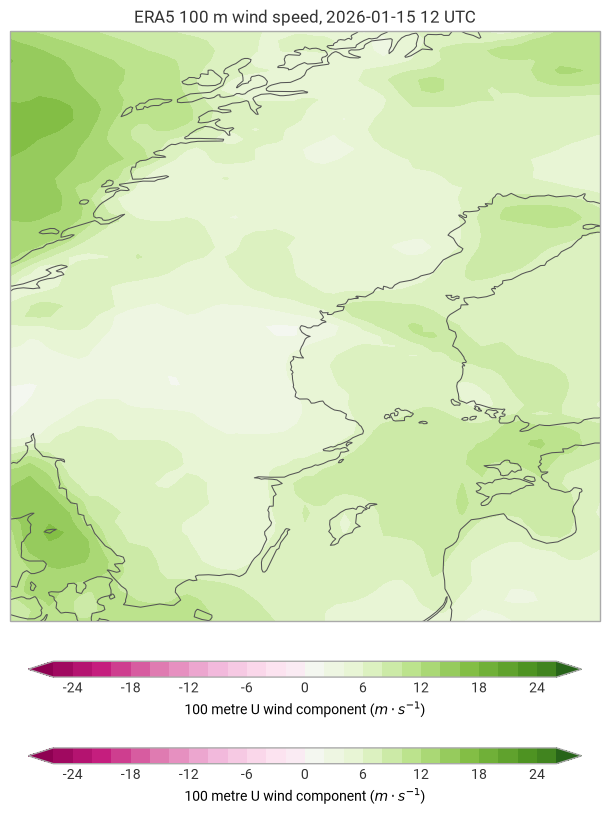

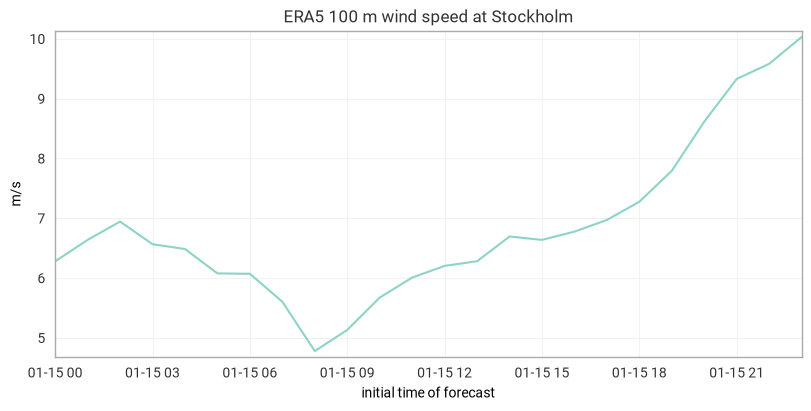

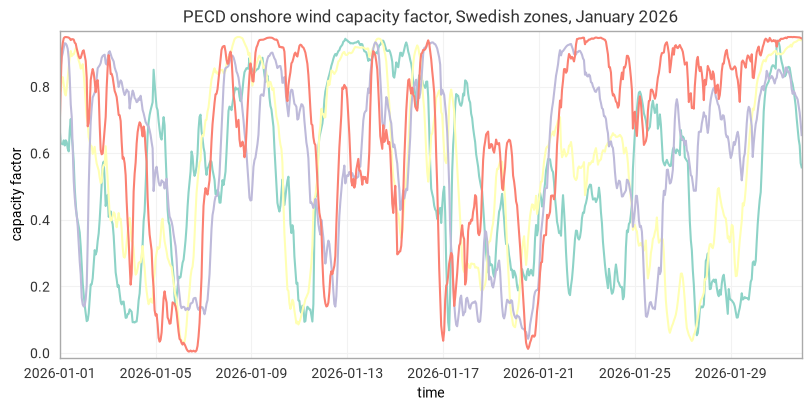

calmest day in the PECD zone series: 2026-01-20 (C2 fetched 2026-01-15)
            SE01  SE02  SE03  SE04
time                              
2026-01-20 0.253 0.315 0.108 0.169
2026-01-15 0.862 0.614 0.608 0.607


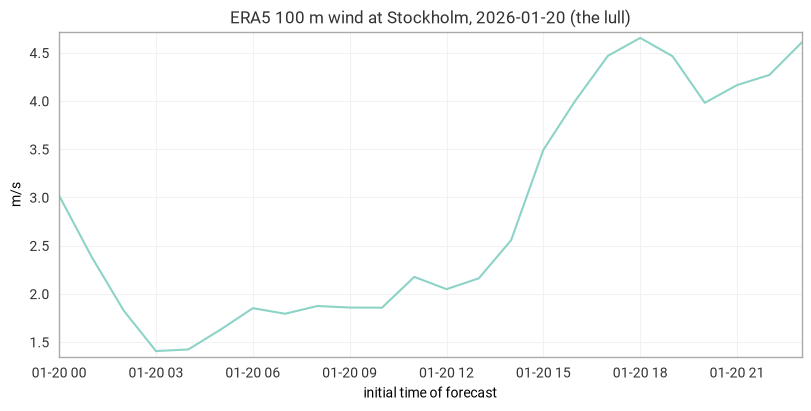


ERA5 Stockholm 100 m wind:
  2026-01-15 (windy):  4.8 - 10.0 m/s, PECD zone CF 0.673
  2026-01-20 (lull) :  1.4 -  4.7 m/s, PECD zone CF 0.211
-> the same lull, one grid point and four zone aggregates apart.


In [25]:
# C5
import earthkit.plots as ekp

# 1. a map. ekwind.speed takes a FieldList and hands one back, so the geography
#    survives the arithmetic -- to_numpy() first would have thrown it away.
speed_fl = ekwind.speed(u_fl, v_fl)
HOUR = 12
chart = ekp.quickplot(speed_fl[HOUR])  # draws its own coastlines
chart.title(f"ERA5 100 m wind speed, 2026-01-15 {HOUR:02d} UTC")
chart.legend()
chart.show()

# 2. the Stockholm point, hour by hour
point_speed = ekwind.speed(point["100u"], point["100v"]).rename("100m wind speed")
series = ekp.timeseries.line(point_speed, title="ERA5 100 m wind speed at Stockholm")
series.ylabel("m/s")
series.show()

# 3. the PECD zones over the whole month, on one chart
peon_se = frames["peon"].set_index("ts")[swedish["peon"]].rename_axis("time")
zones = ekp.timeseries.line(
    peon_se.to_xarray(),
    overlay=True,
    title="PECD onshore wind capacity factor, Swedish zones, January 2026",
)
zones.ylabel("capacity factor")
zones.legend()
zones.show()

# 4. the same lull from both sides. 2026-01-15 turns out to be a windy day, so take
#    the calmest day the PECD zones show and pull that ERA5 day to sit next to it.
daily = peon_se.resample("D").mean()
lull = daily.mean(axis=1).idxmin()
print(f"calmest day in the PECD zone series: {lull.date()} (C2 fetched 2026-01-15)")
print(daily.loc[[lull, pd.Timestamp("2026-01-15")]].to_string(float_format=lambda v: f"{v:.3f}"))

lull_src = ekd.from_source("cds", ERA5, wind_req | {"day": f"{lull.day:02d}"})
lull_ds = lull_src.to_xarray()
lull_point = ekwind.speed(
    lull_ds["100u"].sel(**STOCKHOLM, method="nearest"),
    lull_ds["100v"].sel(**STOCKHOLM, method="nearest"),
).rename(f"100m wind speed, {lull.date()}")
both_days = ekp.timeseries.line(
    lull_point, title=f"ERA5 100 m wind at Stockholm, {lull.date()} (the lull)"
)
both_days.ylabel("m/s")
both_days.show()

print(
    f"\nERA5 Stockholm 100 m wind:"
    f"\n  2026-01-15 (windy): {float(point_speed.min()):4.1f} - {float(point_speed.max()):4.1f} m/s,"
    f" PECD zone CF {daily.loc['2026-01-15'].mean():.3f}"
    f"\n  {lull.date()} (lull) : {float(lull_point.min()):4.1f} - {float(lull_point.max()):4.1f} m/s,"
    f" PECD zone CF {daily.loc[lull].mean():.3f}"
    "\n-> the same lull, one grid point and four zone aggregates apart."
)

### C6. Decoders, and where the size cliff is

**Goal:** map which return type you get per product, and build the habit of checking size
first.

**Tasks:**

1. Call `ekd.from_source("cds", ...)` for three shapes; record `type(src)` and which `to_*`
   methods work.
   - PECD `nuts_0` CSV → you saw this in S4
   - global-reanalysis `admin_0` with `file_format="csv"`
   - ERA5 GRIB from C2
2. Now the gridded energy product: `file_format="netcdf_4"`,
   `spatial_resolution="0_25_degree"`, `1_hour`, one month. **Do not call `from_source` on
   it first** — earthkit downloads as part of the call, so there is no size check to be had
   afterwards. Price it with `glob.estimate_costs(req)`, get the real byte count from
   `cds.submit_and_wait_on_results(GLOB, req).content_length`, and only then decide.
3. Write down the rule you will actually follow.

**Docs:** [pandas tutorial](https://earthkit-data.readthedocs.io/en/latest/tutorials/other/pandas.html) ·
[netCDF](https://earthkit-data.readthedocs.io/en/latest/tutorials/netcdf/netcdf.html) ·
[datastores API](https://ecmwf.github.io/ecmwf-datastores-client/_api/datastores/index.html) for `estimate_costs` and
`submit_and_wait_on_results`

**Why the order matters:** `Results.content_length` is the safety valve `from_source` does
not give you — the one concrete reason to drop below earthkit.

**A number for calibration:** `sis-energy-derived-projections` has no year selector, so one
variable at 3-hourly country level is a single **118 MB** file. That is the floor, not an
overreach.


In [26]:
# C6
# 1. what comes back, per product shape (all three are already cached)
shapes = [
    ("PECD nuts_0 CSV", PECD, temp_req),
    ("global-reanalysis admin_0 CSV", GLOB, glob_req),
    ("ERA5 single-levels GRIB", ERA5, wind_req),
]
for label, dataset, request in shapes:
    source = ekd.from_source("cds", dataset, request)
    decoders = [a for a in dir(source) if a.startswith("to_")]
    print(f"{label:30s} {type(source).__name__:10s} {decoders}")

# 2. the gridded product -- priced, not downloaded.
#    spatial_coverage must be 'global' here: there is no europe block at 0.25 deg.
grid_req = {
    "variable": ["2m_temperature"],
    "spatial_coverage": "global",
    "spatial_resolution": "0_25_degree",
    "temporal_resolution": "1_hour",
    "year": "2026",
    "month": "01",
    "version": "1_00",
    "file_format": "netcdf_4",
}
assert glob.apply_constraints(grid_req).get("variable"), "not a selectable combination"
print("\nestimate_costs:", glob.estimate_costs(grid_req))

results = cds.submit_and_wait_on_results(GLOB, grid_req)
print(
    f"content_length : {results.content_length:,} bytes"
    f" = {results.content_length / 1e6:,.0f} MB ({results.content_type})"
)
print(
    f"the CSV next to it: {Path(ekd.from_source('cds', GLOB, glob_req).path).stat().st_size / 1e3:,.0f} kB"
)

# 3. the rule
print("""
Rule I will follow:

  CSV regional products (nuts_0/szon/peon/admin_0, one variable, one month) are a few
  hundred kB. Call from_source and stop thinking about it.

  Anything gridded, or anything without a year/month selector, gets priced first:
    costs  = collection.estimate_costs(req)        # instant, and validates the request
    length = cds.submit_and_wait_on_results(ds, req).content_length
  and only then from_source. estimate_costs alone is not enough -- it reported
  cost=150 of a 2000 limit for a request that turns out to be ~484 MB zipped, because
  its units are the portal's own request-size score, not bytes. content_length is the
  only number in bytes you can get before the file lands on disk.

  Trigger for the check: file_format='netcdf_4' or spatial_resolution='0_25_degree',
  a request spanning more than one month, or any dataset whose constraints carry no
  year/month field at all (sis-energy-derived-projections: one variable at 3-hourly
  country level is a single ~118 MB file, and there is no smaller slice to ask for).
""")

PECD nuts_0 CSV                CSVData    ['to_array', 'to_featurelist', 'to_fieldlist', 'to_geopandas', 'to_numpy', 'to_pandas', 'to_target', 'to_value', 'to_xarray']
global-reanalysis admin_0 CSV  CSVData    ['to_array', 'to_featurelist', 'to_fieldlist', 'to_geopandas', 'to_numpy', 'to_pandas', 'to_target', 'to_value', 'to_xarray']
ERA5 single-levels GRIB        GribData   ['to_array', 'to_featurelist', 'to_fieldlist', 'to_geopandas', 'to_numpy', 'to_pandas', 'to_target', 'to_value', 'to_xarray']



estimate_costs: {'id': 'size', 'cost': 150.0, 'limit': 2000.0}


content_length : 483,556,919 bytes = 484 MB (application/zip)
the CSV next to it: 703 kB

Rule I will follow:

  CSV regional products (nuts_0/szon/peon/admin_0, one variable, one month) are a few
  hundred kB. Call from_source and stop thinking about it.

  Anything gridded, or anything without a year/month selector, gets priced first:
    costs  = collection.estimate_costs(req)        # instant, and validates the request
    length = cds.submit_and_wait_on_results(ds, req).content_length
  and only then from_source. estimate_costs alone is not enough -- it reported
  cost=150 of a 2000 limit for a request that turns out to be ~484 MB zipped, because
  its units are the portal's own request-size score, not bytes. content_length is the
  only number in bytes you can get before the file lands on disk.

  Trigger for the check: file_format='netcdf_4' or spatial_resolution='0_25_degree',
  a request spanning more than one month, or any dataset whose constraints carry no
  year/month field

---

# Reference

## Docs index

| topic                             | link                                                                                                       |
| --------------------------------- | ---------------------------------------------------------------------------------------------------------- |
| earthkit-data — getting started   | https://earthkit-data.readthedocs.io/en/latest/getting-started.html                                        |
| earthkit-data — API reference     | https://earthkit-data.readthedocs.io/en/latest/api-reference.html                                          |
| earthkit-data — `from_source`     | https://earthkit-data.readthedocs.io/en/latest/concepts/inputs/from_source.html                            |
| earthkit-data — CDS source        | https://earthkit-data.readthedocs.io/en/latest/tutorials/source/cds.html                                   |
| earthkit-data — fieldlists        | https://earthkit-data.readthedocs.io/en/latest/concepts/fieldlist.html                                     |
| earthkit-data — metadata keys     | https://earthkit-data.readthedocs.io/en/latest/concepts/field/keys.html                                    |
| earthkit-data — GRIB overview     | https://earthkit-data.readthedocs.io/en/latest/tutorials/grib/grib_overview.html                           |
| earthkit-data — selection         | https://earthkit-data.readthedocs.io/en/latest/tutorials/grib/grib_selection.html                          |
| earthkit-data — nearest gridpoint | https://earthkit-data.readthedocs.io/en/latest/tutorials/grib/grib_nearest_gridpoint.html                  |
| earthkit-data — xarray            | https://earthkit-data.readthedocs.io/en/latest/concepts/xarray/overview.html                               |
| earthkit-data — pandas            | https://earthkit-data.readthedocs.io/en/latest/tutorials/other/pandas.html                                 |
| earthkit-data — caching           | https://earthkit-data.readthedocs.io/en/latest/concepts/caching.html                                       |
| earthkit-data — config            | https://earthkit-data.readthedocs.io/en/latest/concepts/config.html                                        |
| earthkit-data — 1.0 migration     | https://earthkit-data.readthedocs.io/en/latest/release-notes/migration_1.0.0.html                          |
| earthkit-meteo — wind API         | https://earthkit-meteo.readthedocs.io/en/latest/autoapi/earthkit/meteo/wind/index.html                     |
| earthkit-plots — quickplot        | https://earthkit-plots.readthedocs.io/en/latest/generated/earthkit.plots.quickplot.html                    |
| earthkit-plots — time series      | https://earthkit-plots.readthedocs.io/en/latest/examples/examples/time-series/timeseries-introduction.html |
| datastores client — API           | https://ecmwf.github.io/ecmwf-datastores-client/_api/datastores/index.html                                 |
| CDS — API credentials             | https://cds.climate.copernicus.eu/how-to-api                                                               |

## If you get stuck

| stuck on                   | try                                                                      |
| -------------------------- | ------------------------------------------------------------------------ |
| catalogue metadata         | `Collection` attributes; `dir()` on it                                   |
| a request that 400s        | your A2 validator, then `apply_constraints`                              |
| joint validity             | filter blocks offline; `apply_constraints` is authoritative              |
| cost before download       | `collection.estimate_costs(req)`                                         |
| real size before download  | `cds.submit_and_wait_on_results(ds, req).content_length`                 |
| a 403 on retrieval         | S1 — the licence gate                                                    |
| reading a CSV product      | S4 for the decode, B1 for the `#` header                                 |
| an API name you can't find | `dir(obj)` beats searching — several names here are not what you'd guess |

## Three traps, learned the hard way

- **Unioning constraint blocks invents invalid combinations.** Check validity within a
  single block, or just ask `apply_constraints`.
- **`from_source` returns a wrapper, not a fieldlist**, and `sel()` with a bare key returns
  an _empty_ fieldlist instead of erroring. Use the keys `ls()` prints.
- **Hand-rolled job polling is easy to get wrong.** An earlier version of the companion
  notebook whitelisted `successful`/`failed`/`dismissed` as terminal and hung for 20
  minutes on a `rejected` job. Letting the client own the polling removes that class of bug
  — the real argument for using a client over raw HTTP.


In [27]:
def _widget_values(node):
    d = node.get("details", node)
    v = list(d.get("values", []))
    for g in d.get("groups", []):
        v.extend(_widget_values(g))
    return v


_vw = next(w for w in pecd.form if w["name"] == "variable")
_v = _widget_values(_vw)
print(len(_v), "variables; 2m_temperature in:", "2m_temperature" in _v)
_b = pecd.constraints
_jan = [
    i
    for i, b in enumerate(_b)
    if "2m_temperature" in b.get("variable", [])
    and "2026" in b.get("year", [])
    and "01" in b.get("month", [])
]
print("blocks for 2026-01:", _jan)
for i in _jan:
    print({k: v for k, v in _b[i].items() if k not in {"variable", "year", "month"}})


35 variables; 2m_temperature in: True


blocks for 2026-01: [1, 4, 33, 34, 37]
{'emission_scenario': ['ssp2_4_5'], 'origin': ['cmcc_cm2_sr5', 'ec_earth3', 'mpi_esm1_2_hr'], 'pecd_version': ['deprecated'], 'spatial_resolution': ['0_25_degree'], 'temporal_period': ['future_projections']}
{'file_version': ['fv1'], 'origin': ['era5_reanalysis'], 'pecd_version': ['pecd4_2'], 'spatial_resolution': ['0_25_degree'], 'temporal_period': ['historical']}
{'file_version': ['fv1'], 'origin': ['era5_reanalysis'], 'pecd_version': ['pecd4_2'], 'spatial_resolution': ['city'], 'temporal_period': ['historical']}
{'file_version': ['fv1'], 'origin': ['era5_reanalysis'], 'pecd_version': ['pecd4_2'], 'spatial_resolution': ['nuts_0', 'nuts_2', 'p2of', 'p2on', 'peof', 'peon', 'szof'], 'temporal_period': ['historical']}
{'file_version': ['fv1'], 'origin': ['era5_reanalysis'], 'pecd_version': ['pecd4_2'], 'spatial_resolution': ['szon'], 'temporal_period': ['historical']}
